# Multivariate Time-Series Prediction of Appliance Energy Use Using Deep Learning
**Framework:** TensorFlow / Keras  |  **Environment:** Google Colab (GPU recommended)

| | |
|---|---|
| Name | Piratheepan M. |
| Date | 13/10/2026 |
| GitHub repository | https://github.com/Piratheepan22/Appliance_Energy_Forecasting.git |

---
## About this notebook
The goal is to predict how much energy (in Wh) the household appliances will use in the **next 10 minutes**, using the past readings of a multivariate sensor dataset (indoor temperature and humidity, outdoor weather, lights, and the appliance energy itself). A second check at the end predicts **one hour ahead**.

**Plan**
1. Look at the data and clean it (missing values, outliers).
2. Build new features that describe time, recent history and the relationship between sensors.
3. Keep only the features that really help.
4. Train simple baseline models first, so we know what "good" looks like.
5. Train deep learning models (MLP, LSTM, GRU, CNN-LSTM), compare them, then tune the best one.
5b. Combine two tuned networks (one trained on raw values, one on log values) into a final blend.
6. Test the final model on data it has never seen (the last 20% of the time line).

**Contents**
0. Setup  |  1. Load data  |  2. Exploratory data analysis  |  3. Preprocessing  |  4. Feature engineering  |  5. Feature selection  |  6. Scaling and sequence windows  |  7. Baseline models  |  8. Deep learning model design  |  9. Model comparison and optimisation  |  10. Final models and test evaluation  |  11. One-hour-ahead check  |  12. Saving results  |  13. Summary

**How to run:** open in Google Colab, choose *Runtime > Change runtime type > GPU (T4)*, then *Runtime > Run all*. If the dataset is not found, a file-upload box appears: upload `energy_data_set.csv`. A full run trains about 60 small networks and takes roughly 60-90 minutes on a Colab T4 GPU (estimate); keep the browser tab open. Set `QUICK_RUN = True` in section 0.2 for a 3-minute test run.

## 0. Setup

In [ ]:
# 0.1 Imports
import os, json, random, time, zipfile, warnings
from pathlib import Path
from importlib import metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from numpy.lib.stride_tricks import sliding_window_view

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.feature_selection import RFE
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 100, 'axes.titlesize': 12, 'axes.labelsize': 10})

print('TensorFlow:', tf.__version__)
print('Pandas:', pd.__version__, '| NumPy:', np.__version__)
gpus = tf.config.list_physical_devices('GPU')
print('GPU available:', bool(gpus))
if not gpus:
    print('WARNING: no GPU found. Training will be slow. Use Runtime > Change runtime type > GPU.')

TensorFlow: 2.21.0
Pandas: 2.2.3 | NumPy: 2.1.3
GPU available: True


In [ ]:
# 0.2 Global settings
# Set QUICK_RUN = True for a very fast test run (a few minutes, results are not meaningful).
SEED = 42
QUICK_RUN = False

TARGET = 'Appliances'          # what we want to predict (Wh)
HORIZON = 1                    # 1 step = 10 minutes ahead (main task)
TRAIN_FRACTION = 0.80          # first 80% of the time line = training period
VAL_FRACTION = 0.15            # last 15% of the training period = validation set

# Random Forest sizes
N_TREES = 40 if QUICK_RUN else 200          # final Random Forest baselines
N_TREES_FAST = 20 if QUICK_RUN else 100     # quick forests (ablation, feature selection)

# Neural network training
MAX_EPOCHS = 4 if QUICK_RUN else 50         # upper limit; early stopping decides the real number
PATIENCE = 8                                # early stopping patience (epochs)

# Optimisation plan (how many models we train at each step)
ARCH_SEEDS = [1] if QUICK_RUN else [1, 2]               # seeds used to compare architectures
N_TRIALS = 3 if QUICK_RUN else 16                       # random search trials
CONFIRM_PER_FAMILY = 1 if QUICK_RUN else 2              # best trials re-tested per target family
CONFIRM_SEEDS = [1] if QUICK_RUN else [1, 2, 3]         # seeds used to re-test them
DROPOUT_RATES = [0.0, 0.3] if QUICK_RUN else [0.0, 0.1, 0.2, 0.3, 0.5]
SWEEP_SEEDS = [1] if QUICK_RUN else [1, 2]
FINAL_SEEDS = [42, 7] if QUICK_RUN else [42, 7, 2024, 11, 99]   # seeds of the final ensembles

# Project folders (works from the repository root or from the notebooks/ folder)
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
RAW_DIR, PROC_DIR = ROOT / 'data' / 'raw', ROOT / 'data' / 'processed'
MODEL_DIR = ROOT / 'models'
FIG_DIR, TAB_DIR = ROOT / 'reports' / 'figures', ROOT / 'reports' / 'tables'
for folder in [RAW_DIR, PROC_DIR, MODEL_DIR, FIG_DIR, TAB_DIR]:
    folder.mkdir(parents=True, exist_ok=True)


def set_all_seeds(seed=SEED):
    """Make results as repeatable as possible."""
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)


def save_fig(name):
    """Save the current figure into reports/figures and show it."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()


def save_table(df, name):
    """Save a table into reports/tables as CSV."""
    df.to_csv(TAB_DIR / f'{name}.csv')


set_all_seeds(SEED)
print('Project root:', ROOT)

Project root: /content


## 1. Load the data

In [ ]:
# 1.1 Find and load the dataset
def locate_dataset(filename='energy_data_set.csv'):
    """Look for the CSV in the usual places; ask for an upload in Colab if missing."""
    search_dirs = [RAW_DIR, ROOT, Path('/content'), Path('/content/data/raw')]
    for folder in search_dirs:
        for candidate in sorted(folder.glob('*energy_data_set*.csv')):
            return candidate
    try:
        from google.colab import files
        print('Dataset not found. Please upload energy_data_set.csv')
        uploaded = files.upload()
        uploaded_name = list(uploaded.keys())[0]
        destination = RAW_DIR / filename
        Path(uploaded_name).replace(destination)
        return destination
    except ImportError:
        raise FileNotFoundError(f'Put {filename} inside {RAW_DIR}')


DATA_PATH = locate_dataset()
raw = pd.read_csv(DATA_PATH)
raw['date'] = pd.to_datetime(raw['date'])
raw = raw.sort_values('date').set_index('date').astype('float64')

print('File:', DATA_PATH.name)
print('Shape:', raw.shape)
print('Period:', raw.index.min(), 'to', raw.index.max())
print('Days covered:', (raw.index.max() - raw.index.min()).days)
raw.head()

File: energy_data_set.csv
Shape: (19735, 28)
Period: 2016-01-11 17:00:00 to 2016-05-27 18:00:00
Days covered: 137


,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
date,,,,,,,,,,,,,,,,,,,,,
2016-01-11 17:00:00,60.0,30.0,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
2016-01-11 17:10:00,60.0,30.0,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2016-01-11 17:20:00,50.0,30.0,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
2016-01-11 17:30:00,50.0,40.0,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,45.723333,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
2016-01-11 17:40:00,60.0,40.0,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,45.530000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


**What the columns mean** (from the original dataset description). `Appliances` is the target. `lights` is the energy used by lights. `T1`-`T9` and `RH_1`-`RH_9` are temperature and humidity sensors in different rooms: T1 kitchen, T2 living room, T3 laundry room, T4 office, T5 bathroom, T6 outside (north side), T7 ironing room, T8 teenager room, T9 parents room. `T_out`, `RH_out`, `Press_mm_hg`, `Windspeed`, `Visibility`, `Tdewpoint` come from a nearby weather station. `rv1` and `rv2` are two random numbers added by the dataset authors to test feature selection.

**Differences from assesment requirement.** The brief lists `NSM`, `WeekStatus` and `Day_of_week`, but this file does not contain them. We create all three from the `date` column in section 1.3 (same meaning as in the brief). The file also has extra columns (`T7`-`T9`, `RH_7`-`RH_9`, `Tdewpoint`, `rv1`, `rv2`) which we keep in the analysis.

In [ ]:
# 1.2 Basic quality checks
print('Data types:\n', raw.dtypes.value_counts(), '\n')
print('Duplicate timestamps:', raw.index.duplicated().sum())
step_counts = raw.index.to_series().diff().value_counts()
print('Time steps between rows:\n', step_counts, '\n')
print('rv1 and rv2 identical:', bool((raw['rv1'] == raw['rv2']).all()))
summary = raw.describe().T
save_table(summary, 'data_summary')
summary

Data types:
 float64    28
Name: count, dtype: int64 

Duplicate timestamps: 0
Time steps between rows:
 date
0 days 00:10:00    19734
Name: count, dtype: int64 

rv1 and rv2 identical: True


,count,mean,std,min,25%,50%,75%,max
Appliances,19735.0,97.694958,102.524891,10.000000,50.000000,60.000000,100.000000,1080.000000
lights,19735.0,3.801875,7.935988,0.000000,0.000000,0.000000,0.000000,70.000000
T1,19735.0,21.686571,1.606066,16.790000,20.760000,21.600000,22.600000,26.260000
RH_1,19735.0,40.259739,3.979299,27.023333,37.333333,39.656667,43.066667,63.360000
T2,19735.0,20.341219,2.192974,16.100000,18.790000,20.000000,21.500000,29.856667
RH_2,19735.0,40.420420,4.069813,20.463333,37.900000,40.500000,43.260000,56.026667
T3,19735.0,22.267611,2.006111,17.200000,20.790000,22.100000,23.290000,29.236000
RH_3,19735.0,39.242500,3.254576,28.766667,36.900000,38.530000,41.760000,50.163333
T4,19735.0,20.855335,2.042884,15.100000,19.530000,20.666667,22.100000,26.200000
RH_4,19735.0,39.026904,4.341321,27.660000,35.530000,38.400000,42.156667,51.090000


In [ ]:
# 1.3 Time-ordered split rule 
n_rows = len(raw)
TEST_START = raw.index[int(n_rows * TRAIN_FRACTION)]
print(f'Training period : {raw.index.min()}  ->  {TEST_START - pd.Timedelta(minutes=10)}'
      f'  ({int(n_rows * TRAIN_FRACTION)} rows, 80%)')
print(f'Test period     : {TEST_START}  ->  {raw.index.max()}  ({n_rows - int(n_rows * TRAIN_FRACTION)} rows, 20%)')
print('The last 15% of the training period is kept as a validation set (section 6).')

Training period : 2016-01-11 17:00:00  ->  2016-04-30 08:10:00  (15788 rows, 80%)
Test period     : 2016-04-30 08:20:00  ->  2016-05-27 18:00:00  (3947 rows, 20%)
The last 15% of the training period is kept as a validation set (section 6).


In [ ]:
# 1.4 Calendar helper used by EDA and by feature engineering
# Public holidays in Belgium that fall inside the data period (from dataset search assumed as the dataset from house in Belgium).
BELGIAN_HOLIDAYS = pd.to_datetime(['2016-03-28',   # Easter Monday
                                   '2016-05-01',   # Labour Day
                                   '2016-05-05',   # Ascension Day
                                   '2016-05-16'])  # Whit Monday


def add_time_features(df_in, shift_steps=0):
    """Add calendar features. With shift_steps = h the features describe the moment we
    are predicting (t + h steps). This is safe because the calendar is known in advance."""
    out = df_in.copy()
    ref = df_in.index + pd.Timedelta(minutes=10 * shift_steps)
    hour, minute = np.asarray(ref.hour), np.asarray(ref.minute)
    weekday_mon0 = np.asarray(ref.dayofweek)

    out['NSM'] = hour * 3600 + minute * 60                    # seconds since midnight
    out['hour'] = hour
    out['day_of_week'] = (weekday_mon0 + 1) % 7               # 0 = Sunday ... 6 = Saturday (as in the brief)
    out['is_weekend'] = out['day_of_week'].isin([0, 6]).astype(int)
    out['WeekStatus'] = np.where(out['is_weekend'] == 1, 'Weekend', 'Weekday')
    out['month'] = np.asarray(ref.month)                      # used in EDA only (see section 4)
    out['is_holiday'] = np.asarray(ref.normalize().isin(BELGIAN_HOLIDAYS)).astype(int)
    out['is_day_off'] = ((out['is_weekend'] == 1) | (out['is_holiday'] == 1)).astype(int)

    # Cyclical encoding: 23:50 and 00:00 are close in time, so we use sine/cosine
    tod = 2 * np.pi * out['NSM'] / 86400
    dow = 2 * np.pi * out['day_of_week'] / 7
    out['tod_sin'], out['tod_cos'] = np.sin(tod), np.cos(tod)
    out['dow_sin'], out['dow_cos'] = np.sin(dow), np.cos(dow)
    out['is_night'] = ((hour >= 0) & (hour < 6)).astype(int)
    out['is_evening_peak'] = ((hour >= 17) & (hour < 22)).astype(int)
    return out


eda = add_time_features(raw)
eda[['NSM', 'hour', 'day_of_week', 'WeekStatus', 'is_holiday']].head(3)

,NSM,hour,day_of_week,WeekStatus,is_holiday
date,,,,,
2016-01-11 17:00:00,61200,17,1,Weekday,0
2016-01-11 17:10:00,61800,17,1,Weekday,0
2016-01-11 17:20:00,62400,17,1,Weekday,0


## 2. Exploratory data analysis (EDA)

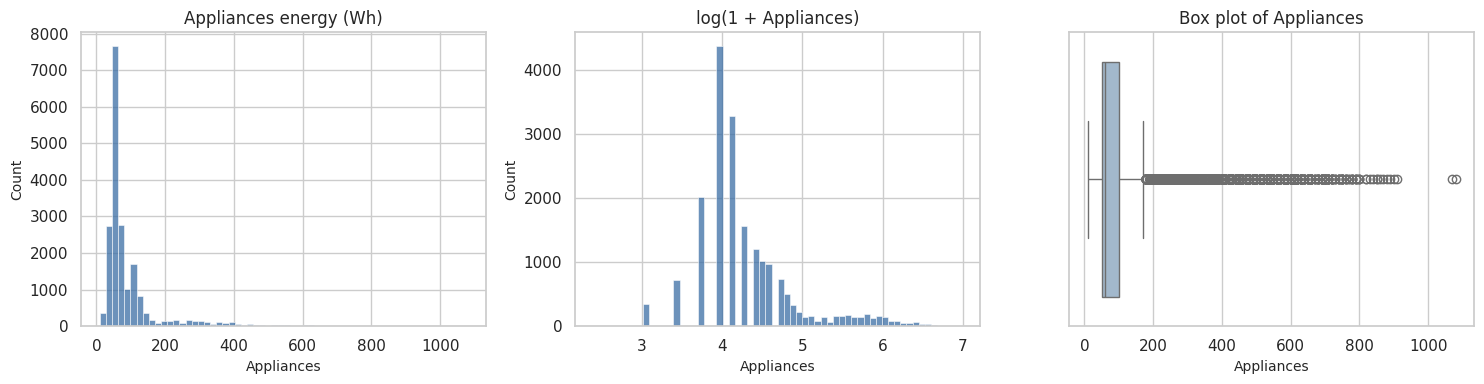

Skewness: 3.39 | Kurtosis: 13.67
Quantiles (Wh):
 0.50      60.0
0.75     100.0
0.90     196.0
0.95     330.0
0.99     576.6
1.00    1080.0
Share of readings at or below 100 Wh: 78.6 %


In [ ]:
# 2.1 The target: how is energy use distributed?
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(raw[TARGET], bins=60, ax=axes[0], color='#3b6ea5')
axes[0].set_title('Appliances energy (Wh)')
sns.histplot(np.log1p(raw[TARGET]), bins=60, ax=axes[1], color='#3b6ea5')
axes[1].set_title('log(1 + Appliances)')
sns.boxplot(x=raw[TARGET], ax=axes[2], color='#9bb8d3')
axes[2].set_title('Box plot of Appliances')
save_fig('eda_target_distribution')

q = raw[TARGET].quantile([0.5, 0.75, 0.9, 0.95, 0.99, 1.0])
print('Skewness:', round(raw[TARGET].skew(), 2), '| Kurtosis:', round(raw[TARGET].kurt(), 2))
print('Quantiles (Wh):\n', q.round(1).to_string())
print('Share of readings at or below 100 Wh:', round((raw[TARGET] <= 100).mean() * 100, 1), '%')

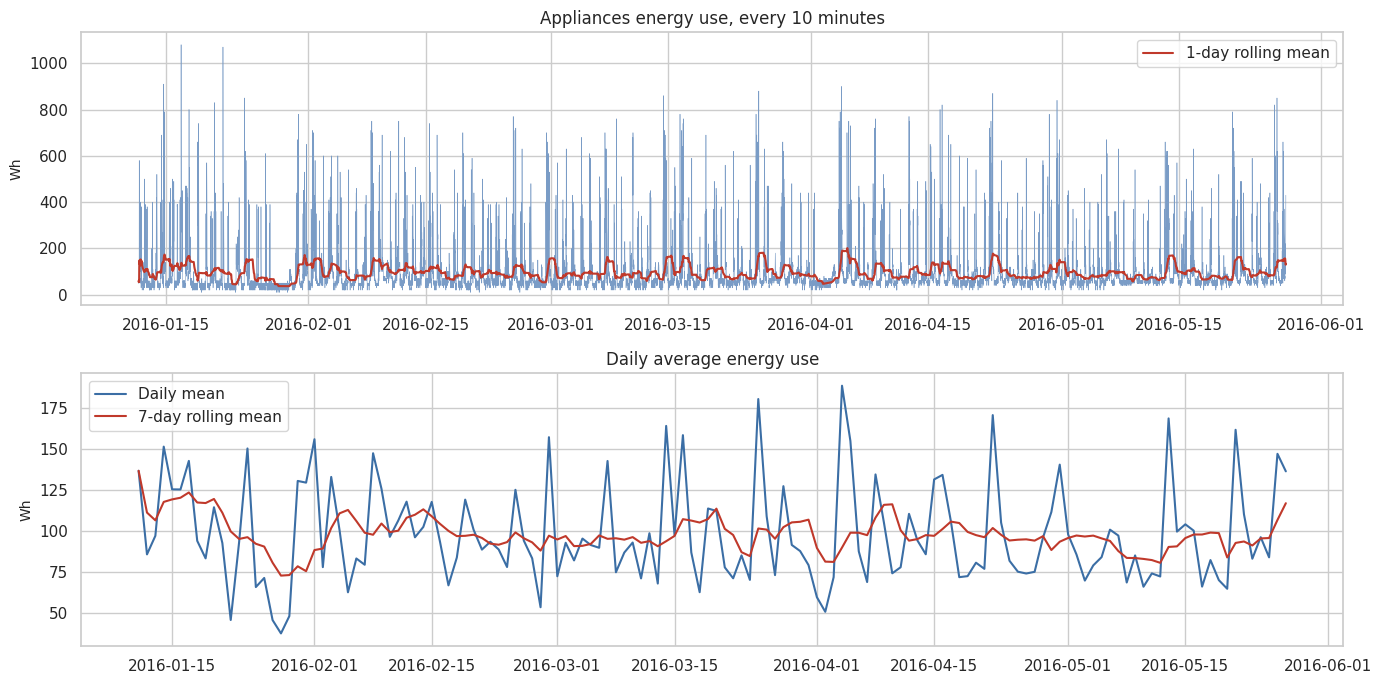

                 count   mean  median     max
Jan (from 11th)   2922   97.0    50.0  1080.0
Feb               4176  100.9    60.0   770.0
Mar               4464   97.0    60.0   880.0
Apr               4320   98.9    60.0   900.0
May (to 27th)     3853   94.2    60.0   850.0


In [ ]:
# 2.2 Energy use over the whole period
daily = raw[TARGET].resample('D').mean()
fig, axes = plt.subplots(2, 1, figsize=(14, 7))
axes[0].plot(raw.index, raw[TARGET], lw=0.4, color='#7a9cc6')
axes[0].plot(raw[TARGET].rolling(144, min_periods=1).mean(), lw=1.5, color='#c0392b', label='1-day rolling mean')
axes[0].set_title('Appliances energy use, every 10 minutes')
axes[0].set_ylabel('Wh')
axes[0].legend()
axes[1].plot(daily.index, daily.values, color='#3b6ea5', label='Daily mean')
axes[1].plot(daily.rolling(7, min_periods=1).mean(), color='#c0392b', label='7-day rolling mean')
axes[1].set_title('Daily average energy use')
axes[1].set_ylabel('Wh')
axes[1].legend()
save_fig('eda_time_series')

monthly = eda.groupby('month')[TARGET].agg(['count', 'mean', 'median', 'max']).round(1)
monthly.index = ['Jan (from 11th)', 'Feb', 'Mar', 'Apr', 'May (to 27th)']
print(monthly)

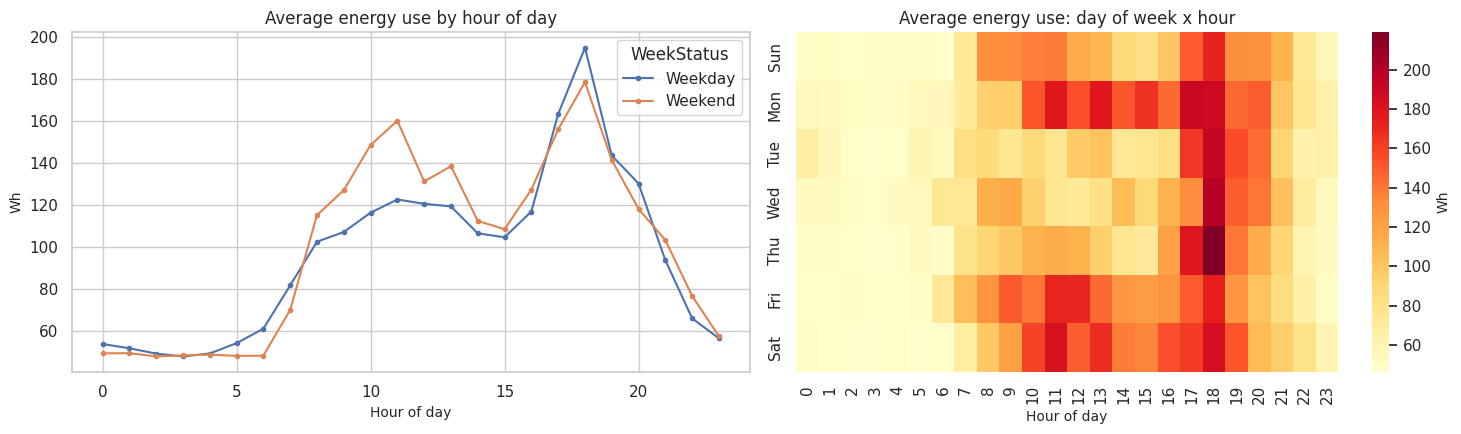

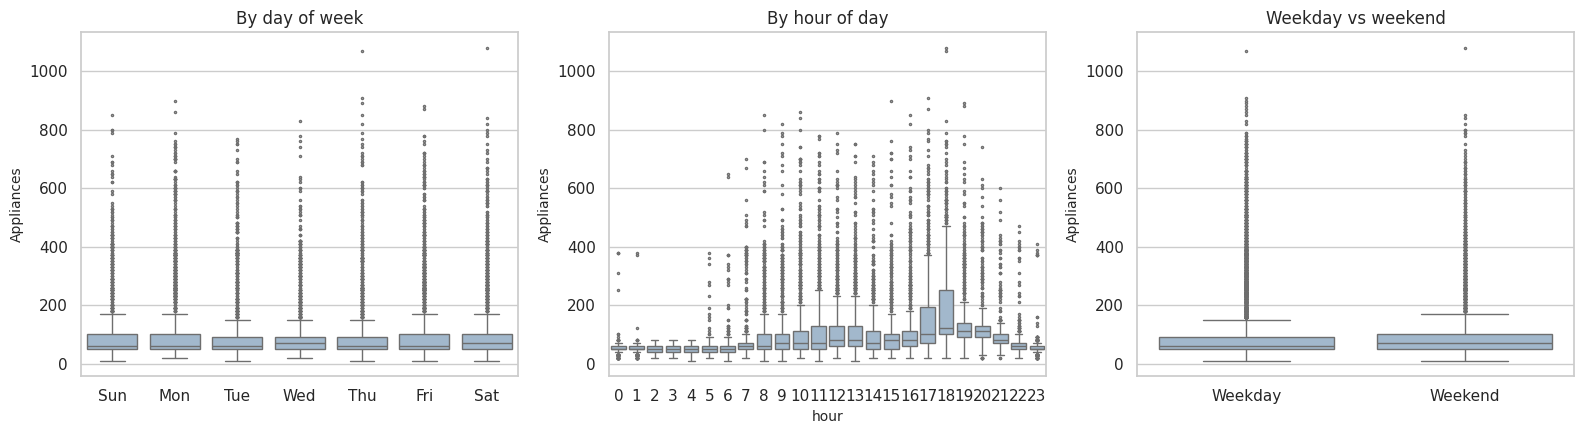

             mean  median    std
WeekStatus                      
Weekday      96.6    60.0  103.1
Weekend     100.6    70.0  101.0


In [ ]:
# 2.3 Daily and weekly patterns
day_names = ['Sun', 'Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat']
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
profile = eda.groupby(['hour', 'WeekStatus'])[TARGET].mean().unstack()
profile.plot(ax=axes[0], marker='o', ms=3)
axes[0].set_title('Average energy use by hour of day')
axes[0].set_xlabel('Hour of day'); axes[0].set_ylabel('Wh')

heat = eda.pivot_table(values=TARGET, index='day_of_week', columns='hour', aggfunc='mean')
heat.index = day_names
sns.heatmap(heat, cmap='YlOrRd', ax=axes[1], cbar_kws={'label': 'Wh'})
axes[1].set_title('Average energy use: day of week x hour')
axes[1].set_xlabel('Hour of day'); axes[1].set_ylabel('')
save_fig('eda_daily_weekly_pattern')

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.boxplot(data=eda, x='day_of_week', y=TARGET, ax=axes[0], color='#9bb8d3', fliersize=1.5)
axes[0].set_xticklabels(day_names); axes[0].set_title('By day of week'); axes[0].set_xlabel('')
sns.boxplot(data=eda, x='hour', y=TARGET, ax=axes[1], color='#9bb8d3', fliersize=1.5)
axes[1].set_title('By hour of day')
sns.boxplot(data=eda, x='WeekStatus', y=TARGET, ax=axes[2], color='#9bb8d3', fliersize=1.5)
axes[2].set_title('Weekday vs weekend'); axes[2].set_xlabel('')
save_fig('eda_boxplots_time')

print(eda.groupby('WeekStatus')[TARGET].agg(['mean', 'median', 'std']).round(1))

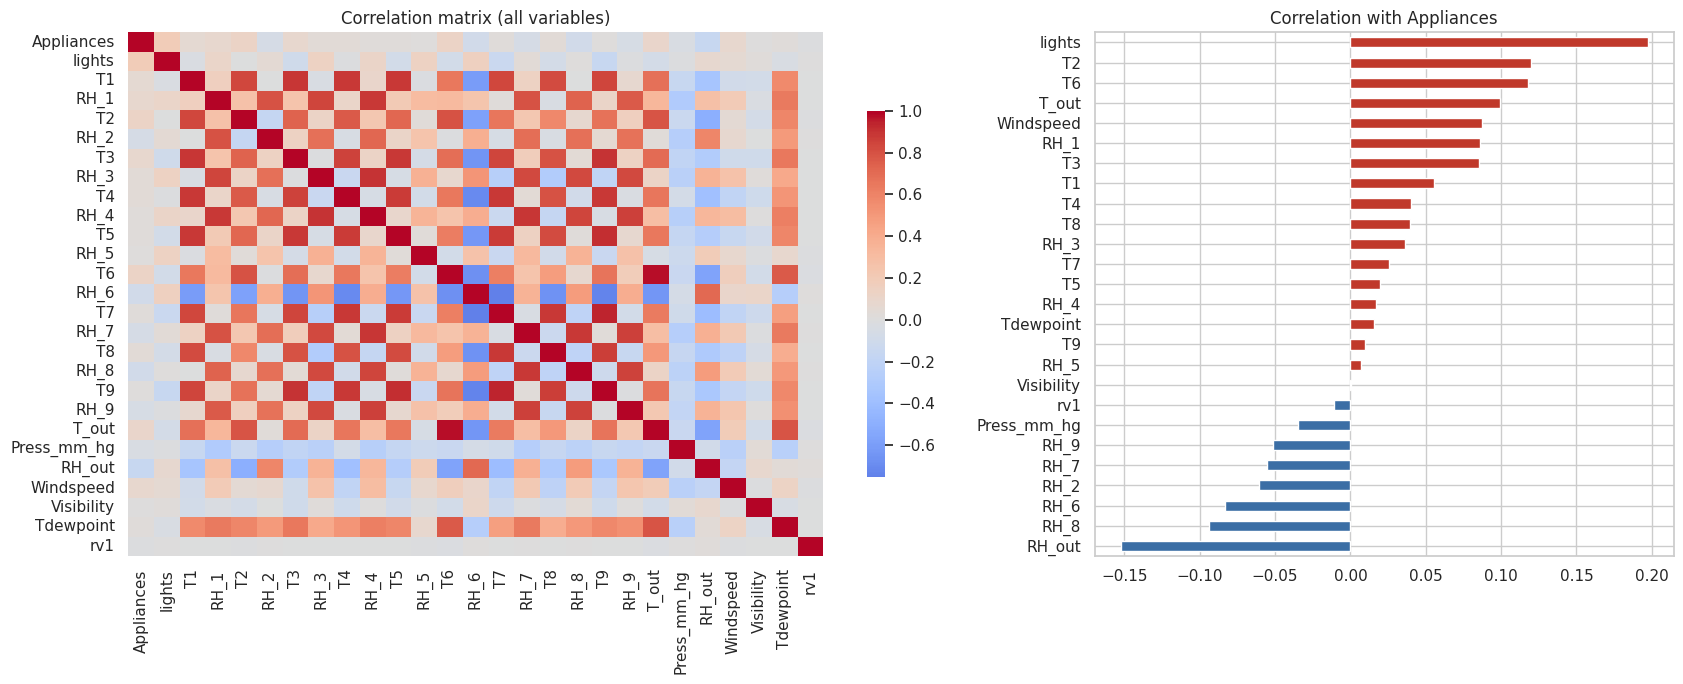

Strongest positive: {'Windspeed': 0.087, 'T_out': 0.099, 'T6': 0.118, 'T2': 0.12, 'lights': 0.197}
Strongest negative: {'RH_out': -0.152, 'RH_8': -0.094, 'RH_6': -0.083, 'RH_2': -0.06, 'RH_7': -0.056}


In [ ]:
# 2.4 Correlations
corr = raw.drop(columns=['rv2']).corr()
fig, axes = plt.subplots(1, 2, figsize=(17, 7), gridspec_kw={'width_ratios': [1.5, 1]})
sns.heatmap(corr, cmap='coolwarm', center=0, ax=axes[0], cbar_kws={'shrink': 0.7},
            xticklabels=True, yticklabels=True)
axes[0].set_title('Correlation matrix (all variables)')
target_corr = corr[TARGET].drop(TARGET).sort_values()
target_corr.plot.barh(ax=axes[1], color=np.where(target_corr > 0, '#c0392b', '#3b6ea5'))
axes[1].set_title('Correlation with Appliances')
save_fig('eda_correlation')
print('Strongest positive:', target_corr.tail(5).round(3).to_dict())
print('Strongest negative:', target_corr.head(5).round(3).to_dict())

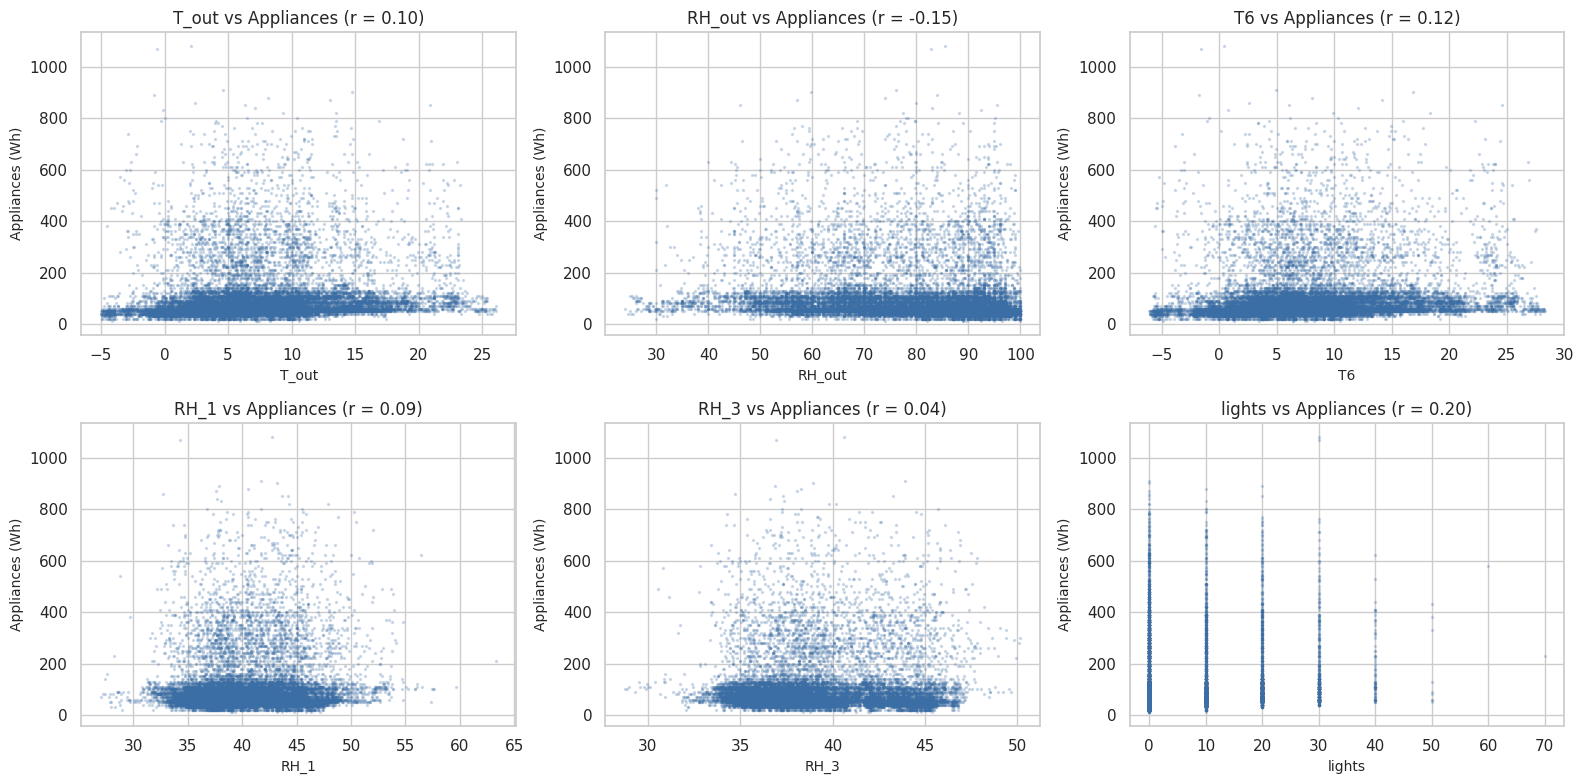

In [ ]:
# 2.5 Sensors, weather and energy use
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), ['T_out', 'RH_out', 'T6', 'RH_1', 'RH_3', 'lights']):
    ax.scatter(raw[col], raw[TARGET], s=2, alpha=0.2, color='#3b6ea5')
    ax.set_xlabel(col); ax.set_ylabel('Appliances (Wh)')
    ax.set_title(f'{col} vs Appliances (r = {raw[col].corr(raw[TARGET]):.2f})')
save_fig('eda_scatter_sensors')

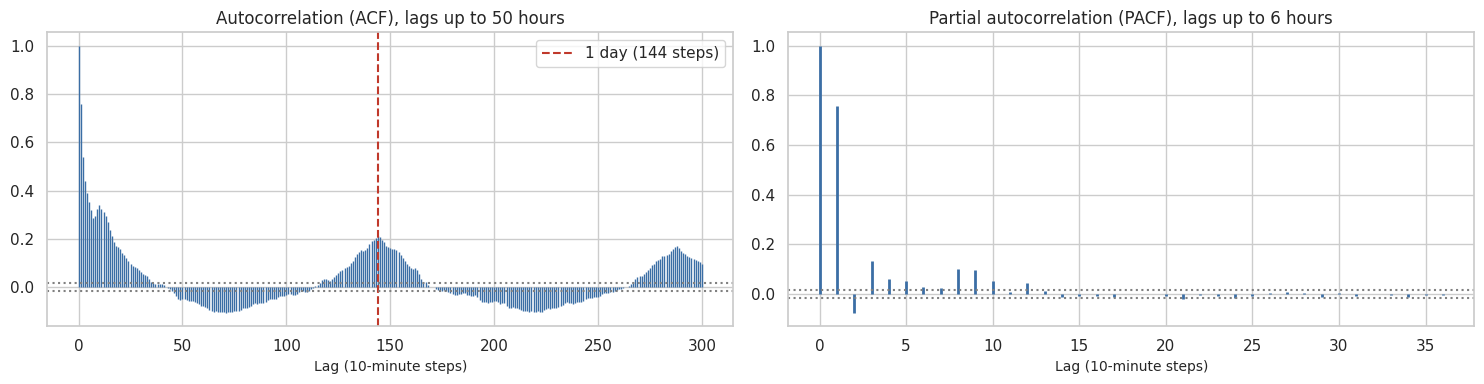

ACF at lag 1, 2, 3, 6, 12, 144: {1: np.float64(0.757), 2: np.float64(0.54), 3: np.float64(0.439), 6: np.float64(0.32), 12: np.float64(0.311), 144: np.float64(0.212)}


In [ ]:
# 2.6 Memory of the series: autocorrelation (computed on the TRAINING period only)
def acf_values(x, nlags):
    """Autocorrelation for lags 0..nlags."""
    x = np.asarray(x, dtype=float) - np.mean(x)
    denom = np.dot(x, x)
    return np.array([np.dot(x[:len(x) - k], x[k:]) / denom for k in range(nlags + 1)])


def pacf_values(x, nlags):
    """Partial autocorrelation (Durbin-Levinson method): the 'direct' effect of each lag."""
    r = acf_values(x, nlags)
    phi = np.zeros((nlags + 1, nlags + 1))
    pacf = np.zeros(nlags + 1)
    pacf[0] = 1.0
    phi[1, 1] = pacf[1] = r[1]
    for k in range(2, nlags + 1):
        num = r[k] - np.sum(phi[k - 1, 1:k] * r[k - 1:0:-1])
        den = 1 - np.sum(phi[k - 1, 1:k] * r[1:k])
        phi[k, k] = pacf[k] = num / den
        for j in range(1, k):
            phi[k, j] = phi[k - 1, j] - phi[k, k] * phi[k - 1, k - j]
    return pacf


train_series = raw.loc[raw.index < TEST_START, TARGET].values
conf = 1.96 / np.sqrt(len(train_series))
acf_long = acf_values(train_series, 300)
pacf_short = pacf_values(train_series, 36)

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].vlines(range(len(acf_long)), 0, acf_long, color='#3b6ea5', lw=1)
axes[0].axvline(144, color='#c0392b', ls='--', label='1 day (144 steps)')
axes[0].axhline(conf, color='grey', ls=':'); axes[0].axhline(-conf, color='grey', ls=':')
axes[0].set_title('Autocorrelation (ACF), lags up to 50 hours'); axes[0].set_xlabel('Lag (10-minute steps)')
axes[0].legend()
axes[1].vlines(range(len(pacf_short)), 0, pacf_short, color='#3b6ea5', lw=2)
axes[1].axhline(conf, color='grey', ls=':'); axes[1].axhline(-conf, color='grey', ls=':')
axes[1].set_title('Partial autocorrelation (PACF), lags up to 6 hours'); axes[1].set_xlabel('Lag (10-minute steps)')
save_fig('eda_acf_pacf')
print('ACF at lag 1, 2, 3, 6, 12, 144:', {k: round(acf_long[k], 3) for k in [1, 2, 3, 6, 12, 144]})

**What the EDA shows**
- **The target is very skewed.** The median is 60 Wh and 75% of readings are 100 Wh or lower, but the maximum is 1080 Wh (skewness about 3.4). Most of the time usage is low, with short, sharp spikes (cooking, washing, heating water). These spikes are the hardest part to predict and will dominate the RMSE.
- **No clear long-term trend.** Monthly averages stay between 94 and 101 Wh, so the level is stable over the four and a half months.
- **There is a clear daily rhythm.** Night-time use is lowest (about 50 Wh from 00:00 to 05:00), it rises from 07:00, stays around 105-135 Wh during the day, and peaks in the evening around 17:00-19:00 (up to about 190 Wh).
- **Weekdays and weekends have similar averages** (97 vs 101 Wh) but a different shape: weekends have a stronger late-morning peak (about 160 Wh at 11:00), while weekdays have a higher evening peak (about 195 Wh at 18:00). This is why we include a weekend/day-off flag together with the hour of day.
- **Single sensors are weakly correlated with the target.** The strongest is `lights` (r = 0.20); indoor temperature sensors are around 0.1 or lower, and outdoor humidity is slightly negative (-0.15). A plain linear model on raw sensors will therefore be weak, and we expect most of the signal to come from the recent history of the target and from time of day.
- **The series has short memory.** Autocorrelation is 0.76 at 10 minutes, then falls to 0.54 (20 min), 0.44 (30 min) and 0.32 (1 hour). A small daily echo remains at one day (0.21). The partial autocorrelation is significant for lags 1-10, 12, 21 and 24, which guides the lag features in section 4.
- `rv1` has a correlation of about -0.01 with the target, as expected for random noise. We use it later as a "noise benchmark" for feature selection.

## 3. Preprocessing
### 3.1 Missing values
**Strategy.** First we detect missing values and missing time steps. If there were gaps, we would fill them with **time-based linear interpolation**, because sensor values such as temperature and humidity change smoothly in time. We would only fill short gaps (up to 1 hour); longer gaps would be flagged. We do not use the mean for time series, because it ignores the time order and would create fake flat values.

The dataset has no missing values, so the experiment below checks the choice: we hide 5% of known values on purpose and see which method recovers them best.

In [ ]:
# 3.1 Detect missing values and missing time steps
missing_per_column = raw.isna().sum()
full_grid = pd.date_range(raw.index.min(), raw.index.max(), freq='10min')
missing_steps = full_grid.difference(raw.index)
print('Total missing values  :', int(missing_per_column.sum()))
print('Missing 10-min steps  :', len(missing_steps), 'of', len(full_grid))


def imputation_experiment(df, columns, fraction=0.05, block=1, seed=SEED):
    """Hide values (single points or blocks) and compare three ways of filling them."""
    rng = np.random.default_rng(seed)
    n = len(df)
    starts = rng.choice(n - block, int(n * fraction / block), replace=False)
    hidden = np.zeros(n, dtype=bool)
    for s in starts:
        hidden[s:s + block] = True
    rows = []
    for col in columns:
        truth = df[col].copy()
        damaged = truth.copy()
        damaged[hidden] = np.nan
        methods = {'Mean fill': damaged.fillna(damaged.mean()),
                   'Forward fill': damaged.ffill().bfill(),
                   'Linear (time) interpolation': damaged.interpolate(method='time').ffill().bfill()}
        for name, filled in methods.items():
            rmse = float(np.sqrt(np.mean((filled[hidden] - truth[hidden]) ** 2)))
            rows.append({'column': col, 'gap': f'{block * 10} min' if block == 1 else f'{block * 10} min blocks',
                         'method': name, 'RMSE': rmse})
    return pd.DataFrame(rows)


test_cols = ['T1', 'RH_1', 'T_out', 'RH_out', 'Appliances']
imputation_results = pd.concat([imputation_experiment(raw, test_cols, block=1),
                                imputation_experiment(raw, test_cols, block=6)])
imputation_table = imputation_results.pivot_table(index=['gap', 'column'], columns='method', values='RMSE').round(3)
save_table(imputation_table, 'imputation_experiment')
imputation_table

Total missing values  : 0
Missing 10-min steps  : 0 of 19735


method                    Forward fill  Linear (time) interpolation  Mean fill
gap           column                                                          
10 min        Appliances        89.626                       60.862    110.148
              RH_1               0.580                        0.313      3.921
              RH_out             0.969                        0.234     14.059
              T1                 0.052                        0.028      1.625
              T_out              0.177                        0.037      4.959
60 min blocks Appliances       118.722                       91.225    111.209
              RH_1               1.540                        1.209      4.251
              RH_out             3.338                        0.944     15.715
              T1                 0.156                        0.053      1.605
              T_out              0.708                        0.156      5.245

**Result.** For the smooth sensor and weather columns, linear interpolation recovers hidden values far better than the mean or forward fill, for both single missing readings and 1-hour gaps. For `Appliances` (a spiky signal) no method is very good, which is expected. Since the real data has no gaps, no value is changed, but the function below is part of the pipeline and would be applied to any new data.

In [ ]:
# 3.1 The cleaning function used by the pipeline (does nothing here, because nothing is missing)
def fill_missing(df, max_gap_steps=6):
    """Put the data on a regular 10-minute grid and fill short gaps by time interpolation."""
    grid = pd.date_range(df.index.min(), df.index.max(), freq='10min')
    out = df.reindex(grid)
    out = out.interpolate(method='time', limit=max_gap_steps, limit_direction='both')
    return out


filled = fill_missing(raw)
print('Rows before:', len(raw), '| after:', len(filled), '| values changed:', int((filled.loc[raw.index] != raw).sum().sum()))
data = filled.copy()

Rows before: 19735 | after: 19735 | values changed: 0


### 3.2 Outliers
**Method.** We count outliers with two common rules: the **IQR rule** (outside 1.5 x IQR from the quartiles) and the **Z-score rule** (more than 3 standard deviations from the mean), and we look at box plots.

**Decision (explained after the tables).**

             IQR outliers  IQR %  Z>3 outliers  Z>3 %
lights               4483  22.72           647   3.28
Visibility           2522  12.78            37   0.19
Appliances           2138  10.83           540   2.74
RH_5                 1330   6.74           567   2.87
T2                    546   2.77           206   1.04
T1                    515   2.61            14   0.07
T6                    515   2.61            98   0.50
T_out                 436   2.21            93   0.47
RH_out                239   1.21           159   0.81
RH_2                  235   1.19           131   0.66
Press_mm_hg           219   1.11           107   0.54
T3                    217   1.10            54   0.27
Windspeed             214   1.08           104   0.53
T4                    186   0.94             0   0.00


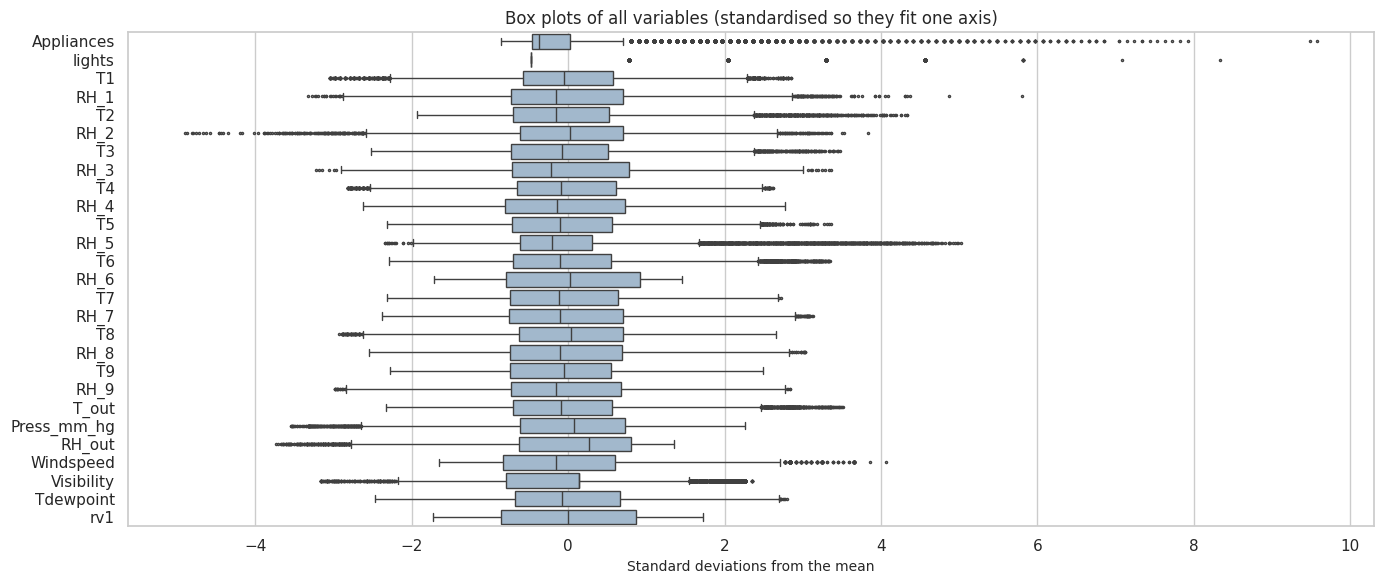


RH_6 readings equal to the minimum value (1.0): 1452 (7.4%)


In [ ]:
# 3.2 Outlier detection
def outlier_table(df):
    """Count outliers per column using the IQR rule and the Z-score rule."""
    q1, q3 = df.quantile(0.25), df.quantile(0.75)
    iqr = q3 - q1
    iqr_count = ((df < q1 - 1.5 * iqr) | (df > q3 + 1.5 * iqr)).sum()
    z = (df - df.mean()) / df.std()
    z_count = (z.abs() > 3).sum()
    table = pd.DataFrame({'IQR outliers': iqr_count, 'IQR %': (iqr_count / len(df) * 100).round(2),
                          'Z>3 outliers': z_count, 'Z>3 %': (z_count / len(df) * 100).round(2)})
    return table.sort_values('IQR %', ascending=False)


outliers = outlier_table(data.drop(columns=['rv2']))
save_table(outliers, 'outlier_table')
print(outliers.head(14))

z_scores = ((data - data.mean()) / data.std()).drop(columns=['rv2'])
fig, ax = plt.subplots(figsize=(14, 6))
sns.boxplot(data=z_scores, orient='h', ax=ax, fliersize=1.5, color='#9bb8d3')
ax.set_title('Box plots of all variables (standardised so they fit one axis)')
ax.set_xlabel('Standard deviations from the mean')
save_fig('preprocessing_outlier_boxplots')

print('\nRH_6 readings equal to the minimum value (1.0):', int((data['RH_6'] <= 1.0).sum()),
      f"({(data['RH_6'] <= 1.0).mean() * 100:.1f}%)")

**Decision and reasons**
1. **`Appliances` (target): outliers are kept.** The high readings (up to 1080 Wh) are real events such as cooking or heating water, not sensor errors. Removing them would make the model look better on paper but useless in reality, because the test set also contains such spikes.
2. **Sensor and weather features: cap only the extreme values.** Extreme sensor values can distort scaling and training, so we cap each sensor/weather column at the "extreme fences" `Q1 - 3 x IQR` and `Q3 + 3 x IQR` (the usual 1.5 x IQR rule is too strict for weather data). The limits are learned **only from the training period**, so no test information leaks in. Rows are never deleted.
   *Why not simple percentile caps?* We first tried the 0.5th / 99.5th percentiles of the training period. That capped about 22,000 values in the test period, because May is warmer than January-April and the test temperatures naturally lie above the training range. Cutting them would remove real information, so we switched to the wider 3 x IQR fences, which only touch genuinely extreme values.
3. **`lights` is left unchanged.** It is mostly 0 with real on-events, so it is not a sensor error.
4. `RH_6` (outdoor humidity on the north side) sits at its lower limit of 1.0% for many readings. This looks like a sensor floor in very dry air rather than a random error. We keep these rows (capping does not change them).

In [ ]:
# 3.2 Apply capping with limits learned from the training period only
CLIP_COLS = ([f'T{i}' for i in range(1, 10)] + [f'RH_{i}' for i in range(1, 10)] +
             ['T_out', 'RH_out', 'Press_mm_hg', 'Windspeed', 'Visibility', 'Tdewpoint'])

train_period = data[data.index < TEST_START]
q1, q3 = train_period[CLIP_COLS].quantile(0.25), train_period[CLIP_COLS].quantile(0.75)
clip_low, clip_high = q1 - 3 * (q3 - q1), q3 + 3 * (q3 - q1)

clean = data.drop(columns=['rv2']).copy()          # rv2 is an exact copy of rv1
clean[CLIP_COLS] = clean[CLIP_COLS].clip(lower=clip_low, upper=clip_high, axis=1)

is_capped = (data[CLIP_COLS] < clip_low) | (data[CLIP_COLS] > clip_high)
n_capped = is_capped.sum()
print('Values capped per column (top 6):\n', n_capped.sort_values(ascending=False).head(6).to_string())
print('Total capped:', int(n_capped.sum()), 'of', data[CLIP_COLS].size, 'values',
      f'({n_capped.sum() / data[CLIP_COLS].size * 100:.2f}%)',
      '| in training period:', int(is_capped[data.index < TEST_START].sum().sum()),
      '| in test period:', int(is_capped[data.index >= TEST_START].sum().sum()))

Values capped per column (top 6):
 RH_5    514
T2      260
RH_2     16
T3       11
RH_1      2
T5        0
Total capped: 803 of 473640 values (0.17%) | in training period: 421 | in test period: 382


### 3.3 Scaling and splitting
Scaling and the final train / validation / test split are done after feature engineering, because the new features need scaling too. They are described in section 6. The split rule (first 80% for training, last 20% for testing, no shuffling) was already fixed in section 1.3.

## 4. Feature engineering
We build features in five groups. Every feature at time *t* uses **only information available at time *t* or earlier**, so there is no leakage from the future. The target for row *t* is the energy use at time *t + 10 minutes*.

| Group | Features | Why |
|---|---|---|
| Calendar | hour, seconds since midnight (NSM), day of week, weekend flag, holiday flag, day-off flag, sine/cosine of time of day and day of week, night flag, evening-peak flag | Daily and weekly rhythm seen in EDA. Sine/cosine let the model know that 23:50 is next to 00:00. |
| Recent history | current value, lags chosen from the partial autocorrelation, rolling mean / std / max / min over 30 min to 24 h, exponential moving averages, change since the last reading, level compared with the 24-hour average, share of the last 3 hours above 100 Wh, steps since the last spike, typical usage at the target time | The series has short memory, so recent history is the strongest signal. |
| Context rolling | rolling lights use, outdoor temperature trend, wind | Smooths noisy weather and lights signals. |
| Interactions | mean indoor temperature and humidity, indoor-outdoor differences, temperature x humidity, wind x temperature difference, kitchen-living room differences, 10-minute, 30-minute and 1-hour changes in kitchen, laundry-room and bathroom humidity and temperature | Cooking, showers and laundry change humidity quickly; heating depends on the indoor-outdoor gap. |
| External | Belgian public holidays inside the data period | Behaviour on holidays is like a weekend. |

**Features we deliberately do not use:** the calendar *month* is not used as a model input. The test period is entirely in May (and the end of April), a month the model never sees during training, so a month feature could not be learned in a useful way. `rv1` and `rv2` are random noise and are used only as a benchmark in section 5.

In [ ]:
# 4.1 Choose lag features using the partial autocorrelation (training period only)
significant = [k for k in range(1, 25) if abs(pacf_short[k]) > conf]
EXTRA_LAGS = [1, 2, 3, 6, 12, 36, 72, 144]      # 10 min, 20 min, 30 min, 1 h, 2 h, 6 h, 12 h, 1 day
LAGS = sorted(set(significant) | set(EXTRA_LAGS))
MAX_LAG = max(LAGS)
print('Lags with significant PACF (1-24):', significant)
print('Final lag list (10-min steps):', LAGS)
print('Warm-up rows dropped at the start:', MAX_LAG)

Lags with significant PACF (1-24): [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 21, 24]
Final lag list (10-min steps): [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 21, 24, 36, 72, 144]
Warm-up rows dropped at the start: 144


In [ ]:
# 4.2 Build the feature table
def steps_since_event(values, threshold=100, cap=144):
    """Number of 10-minute steps since the last reading above the threshold (capped)."""
    counter, out = cap, np.empty(len(values))
    for i, v in enumerate(values):
        counter = 0 if v > threshold else min(counter + 1, cap)
        out[i] = counter
    return out


def build_feature_table(clean_df, lags, horizon):
    """Create all candidate features. Row t describes the situation at time t; the column
    'target' is Appliances at time t + horizon (in 10-minute steps)."""
    d = add_time_features(clean_df, shift_steps=horizon)
    app = clean_df[TARGET]

    # --- recent history of the target ---
    for k in lags:
        d[f'lag_{k}'] = app.shift(k)
    for w in [3, 6, 18, 36, 144]:                              # 30 min, 1 h, 3 h, 6 h, 24 h
        d[f'app_mean_{w}'] = app.rolling(w).mean()
    for w in [6, 18]:
        d[f'app_std_{w}'] = app.rolling(w).std()
        d[f'app_max_{w}'] = app.rolling(w).max()
        d[f'app_min_{w}'] = app.rolling(w).min()
    d['app_momentum'] = app.diff()                              # change since the last reading
    d['app_level_ratio'] = app / d['app_mean_144']              # now compared with the 24-hour average
    d['app_active_share_18'] = (app > 100).rolling(18).mean()   # share of the last 3 hours above 100 Wh
    d['app_ewm_6'] = app.ewm(span=6, adjust=False).mean()
    d['app_ewm_36'] = app.ewm(span=36, adjust=False).mean()
    d['steps_since_spike'] = steps_since_event(app.values)

    # typical use at the target time: mean of earlier days at the same clock time and the same day type
    own = add_time_features(clean_df, shift_steps=0)
    key = pd.DataFrame({'v': app.values, 'day_off': own['is_day_off'].values, 'slot': own['NSM'].values},
                       index=clean_df.index)
    earlier_mean = lambda s: s.shift(1).expanding().mean()          # only earlier days, never the current value
    profile_type = key.groupby(['day_off', 'slot'])['v'].transform(earlier_mean)
    profile_any = key.groupby('slot')['v'].transform(earlier_mean)  # fallback when a day type has no history yet
    profile = pd.Series(profile_type.fillna(profile_any).values, index=clean_df.index)
    d['typical_at_target'] = profile.shift(-horizon)                 # value belongs to the moment we predict
    d['level_vs_typical'] = np.log1p(app) - np.log1p(d['typical_at_target'])   # now compared with the usual level

    # --- rolling context ---
    d['lights_mean_6'] = clean_df['lights'].rolling(6).mean()
    d['T_out_mean_18'] = clean_df['T_out'].rolling(18).mean()
    d['Windspeed_mean_6'] = clean_df['Windspeed'].rolling(6).mean()

    # --- interactions and differences ---
    indoor_t = [f'T{i}' for i in [1, 2, 3, 4, 5, 7, 8, 9]]          # T6 is outside, so it is not part of the indoor mean
    indoor_rh = [f'RH_{i}' for i in [1, 2, 3, 4, 5, 7, 8, 9]]
    d['T_in_mean'] = clean_df[indoor_t].mean(axis=1)
    d['RH_in_mean'] = clean_df[indoor_rh].mean(axis=1)
    d['T_diff_in_out'] = d['T_in_mean'] - clean_df['T_out']
    d['RH_diff_in_out'] = d['RH_in_mean'] - clean_df['RH_out']
    d['T_x_RH_in'] = d['T_in_mean'] * d['RH_in_mean'] / 100
    d['T_x_RH_out'] = clean_df['T_out'] * clean_df['RH_out'] / 100
    d['wind_x_T_diff'] = clean_df['Windspeed'] * d['T_diff_in_out']
    d['T_kitchen_minus_living'] = clean_df['T1'] - clean_df['T2']
    d['RH_kitchen_minus_living'] = clean_df['RH_1'] - clean_df['RH_2']
    d['d_RH_1'] = clean_df['RH_1'].diff()
    d['d_RH_3'] = clean_df['RH_3'].diff()
    d['d_T1'] = clean_df['T1'].diff()
    d['d_RH_1_1h'] = clean_df['RH_1'].diff(6)
    # changes over the last 30 minutes in the kitchen, laundry room and bathroom
    d['d_T1_30'] = clean_df['T1'].diff(3)
    d['d_RH_1_30'] = clean_df['RH_1'].diff(3)
    d['d_RH_3_30'] = clean_df['RH_3'].diff(3)
    d['d_RH_5_30'] = clean_df['RH_5'].diff(3)

    d['target'] = app.shift(-horizon)
    d = d.drop(columns=['WeekStatus', 'month'])
    d = d.iloc[MAX_LAG:]                                   # remove warm-up rows
    n_before = len(d)
    d = d.dropna()                                         # removes the last 'horizon' rows (no target)
    return d, n_before - len(d)


feat, n_dropped = build_feature_table(clean, LAGS, HORIZON)
print('Feature table shape:', feat.shape, '| rows dropped at the end (no target):', n_dropped)
print('Any missing values left:', bool(feat.isna().any().any()))
assert (feat.index.to_series().diff().dropna() == pd.Timedelta(minutes=10)).all(), 'time line has gaps'
print('Time line is continuous (every step is exactly 10 minutes).')
feat.to_csv(PROC_DIR / 'feature_table_h1.csv')

# Column groups (used for the ablation study and for the report)
ORIGINAL_COLS = ['lights'] + [f'T{i}' for i in range(1, 10)] + [f'RH_{i}' for i in range(1, 10)] + \
                ['T_out', 'RH_out', 'Press_mm_hg', 'Windspeed', 'Visibility', 'Tdewpoint']
TIME_COLS = ['NSM', 'hour', 'day_of_week', 'is_weekend', 'is_holiday', 'is_day_off', 'tod_sin', 'tod_cos',
             'dow_sin', 'dow_cos', 'is_night', 'is_evening_peak']
HISTORY_COLS = [TARGET] + [f'lag_{k}' for k in LAGS] + [c for c in feat.columns if c.startswith(('app_', 'steps_since'))] + \
               ['typical_at_target', 'level_vs_typical']
CONTEXT_COLS = ['lights_mean_6', 'T_out_mean_18', 'Windspeed_mean_6']
INTERACTION_COLS = ['T_in_mean', 'RH_in_mean', 'T_diff_in_out', 'RH_diff_in_out', 'T_x_RH_in', 'T_x_RH_out',
                    'wind_x_T_diff', 'T_kitchen_minus_living', 'RH_kitchen_minus_living', 'd_RH_1', 'd_RH_3',
                    'd_T1', 'd_RH_1_1h', 'd_T1_30', 'd_RH_1_30', 'd_RH_3_30', 'd_RH_5_30']
CANDIDATES = ORIGINAL_COLS + TIME_COLS + HISTORY_COLS + CONTEXT_COLS + INTERACTION_COLS
print('Number of candidate features:', len(CANDIDATES), '| rv1 kept apart as noise probe:', 'rv1' in feat.columns)

Feature table shape: (19590, 95) | rows dropped at the end (no target): 1
Any missing values left: False
Time line is continuous (every step is exactly 10 minutes).
Number of candidate features: 93 | rv1 kept apart as noise probe: True


**Checking for leakage.** The next cell proves that the features contain no future information: if we change the data *after* time *t*, the features of row *t* must not change.

In [ ]:
# 4.3 Leakage test: features at time t must not depend on data after t
t_check = 8000
modified = clean.copy()
modified.iloc[t_check + 1:, :] = modified.iloc[t_check + 1:, :] * 1.7 + 5          # damage the future
feat_mod, _ = build_feature_table(modified, LAGS, HORIZON)
row_time = feat.index[t_check - MAX_LAG]
cols_to_compare = [c for c in feat.columns if c != 'target']      # the target itself may use the future
same = np.allclose(feat.loc[row_time, cols_to_compare].values.astype(float),
                   feat_mod.loc[row_time, cols_to_compare].values.astype(float))
print('Features at', row_time, 'unchanged when the future is changed:', same)
assert same, 'Leakage detected!'

Features at 2016-03-07 06:20:00 unchanged when the future is changed: True


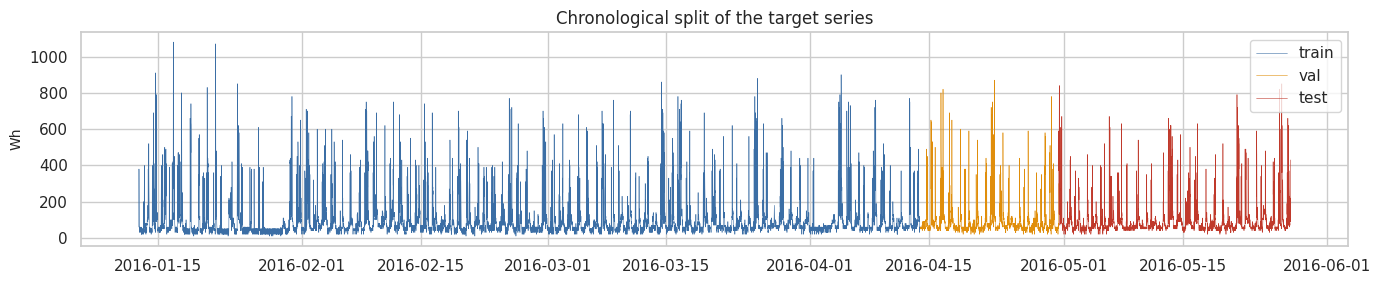

In [ ]:
# 4.4 Split into training, validation and test rows (by the time of the TARGET, in time order)
def make_split_masks(index, horizon):
    """Chronological split. A row belongs to the test set when the time it predicts is in the test period."""
    target_time = index + pd.Timedelta(minutes=10 * horizon)
    in_train_period = np.asarray(target_time < TEST_START)
    test = ~in_train_period
    positions = np.where(in_train_period)[0]
    n_val = int(round(VAL_FRACTION * len(positions)))
    val = np.zeros(len(index), dtype=bool)
    val[positions[-n_val:]] = True
    train = in_train_period & ~val
    first_val = positions[-n_val]
    train[max(first_val - horizon, 0):first_val] = False        # small gap so train labels do not touch validation
    return {'train': train, 'val': val, 'test': test}


masks = make_split_masks(feat.index, HORIZON)
split_table = pd.DataFrame({
    'rows': {k: int(v.sum()) for k, v in masks.items()},
    'from': {k: feat.index[v].min() for k, v in masks.items()},
    'to': {k: feat.index[v].max() for k, v in masks.items()}})
split_table['share %'] = (split_table['rows'] / split_table['rows'].sum() * 100).round(1)
save_table(split_table, 'data_split')
split_table

fig, ax = plt.subplots(figsize=(14, 3))
for name, color in [('train', '#3b6ea5'), ('val', '#e08e0b'), ('test', '#c0392b')]:
    ax.plot(feat.index[masks[name]], feat['target'][masks[name]], lw=0.4, color=color, label=name)
ax.set_title('Chronological split of the target series'); ax.set_ylabel('Wh'); ax.legend(markerscale=5)
save_fig('split_overview')

In [ ]:
# 4.5 Checking the impact of feature engineering, Add the feature groups step by step (Random Forest, validation set)
def make_forest(n_trees=N_TREES, seed=SEED):
    """Random Forest used for baselines, the ablation study and feature selection."""
    return RandomForestRegressor(n_estimators=n_trees, min_samples_leaf=5, max_features=0.5,
                                 n_jobs=-1, random_state=seed)


def regression_metrics(y_true, y_pred):
    """MAE, RMSE, MAPE (%) and R-squared."""
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    return {'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': float(np.sqrt(mean_squared_error(y_true, y_pred))),
            'MAPE %': float(np.mean(np.abs((y_true - y_pred) / y_true)) * 100),
            'R2': r2_score(y_true, y_pred)}


def validation_score(metrics, reference):
    """One balanced number for comparing models: MAE and RMSE, each divided by the error of the
    persistence baseline on the same data, then averaged. 1.0 = as good as persistence, lower is better."""
    return 0.5 * (metrics['MAE'] / reference['MAE'] + metrics['RMSE'] / reference['RMSE'])


y_all = feat['target'].values
persistence_val = regression_metrics(y_all[masks['val']], feat.loc[masks['val'], TARGET])
print('Persistence on the validation set:', {k: round(v, 2) for k, v in persistence_val.items()})

ablation_steps = [('Original sensors only', ORIGINAL_COLS),
                  ('+ calendar features', ORIGINAL_COLS + TIME_COLS),
                  ('+ recent history (lags, rolling)', ORIGINAL_COLS + TIME_COLS + HISTORY_COLS),
                  ('+ context and interactions (all)', CANDIDATES)]
ablation_rows = []
for name, cols in ablation_steps:
    forest = make_forest(N_TREES_FAST).fit(feat.loc[masks['train'], cols], y_all[masks['train']])
    m = regression_metrics(y_all[masks['val']], forest.predict(feat.loc[masks['val'], cols]))
    ablation_rows.append({'Feature set': name, 'n features': len(cols), 'Val MAE': m['MAE'], 'Val RMSE': m['RMSE'],
                          'Val R2': m['R2'], 'Score': validation_score(m, persistence_val)})
ablation = pd.DataFrame(ablation_rows).set_index('Feature set').round(3)
save_table(ablation, 'feature_group_ablation')
ablation

Persistence on the validation set: {'MAE': 27.59, 'RMSE': 69.93, 'MAPE %': 22.63, 'R2': 0.48}


,n features,Val MAE,Val RMSE,Val R2,Score
Feature set,,,,,
Original sensors only,25,73.762,111.607,-0.334,2.135
+ calendar features,37,60.015,101.152,-0.096,1.811
"+ recent history (lags, rolling)",73,27.896,58.673,0.631,0.925
+ context and interactions (all),93,27.968,58.297,0.636,0.924


**How to read this table.** Each row adds one group of features. A negative R-squared means the model is worse than always guessing the average. Compare the rows to see which group brings the biggest gain, and whether the last group (context and interactions) still helps once the history features are present. The feature selection step in section 5 then decides which individual features stay.

## 5. Feature selection
We have about 90 candidate features, and many of them are similar to each other (for example the lags and rolling means). Too many overlapping inputs make a neural network noisier and slower, so we keep only what helps. Everything in this section uses the **training rows only**, and the validation rows to judge the result.

Three steps:
1. **Correlation filter:** if two features are almost identical (correlation above 0.98) we keep only one.
2. **Noise benchmark:** we add two random columns (`rv1` from the dataset and our own `noise_probe`). A feature that is not more important than random noise is not useful.
3. **Recursive Feature Elimination (RFE):** a Random Forest repeatedly drops its least important features and gives a ranking.

Finally we compare several candidate feature sets on the validation set and take the smallest set that is as good as the best one.

In [ ]:
# 5.1 Correlation filter (training rows only)
rng = np.random.default_rng(SEED)
selection_frame = feat[CANDIDATES].copy()
selection_frame['rv1'] = feat['rv1']
selection_frame['noise_probe'] = rng.standard_normal(len(feat))
X_train_sel = selection_frame[masks['train']]
y_train_sel = y_all[masks['train']]

corr_matrix = X_train_sel[CANDIDATES].corr().abs()
upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1))
redundant = [col for col in upper_triangle.columns if (upper_triangle[col] > 0.98).any()]
survivors = [c for c in CANDIDATES if c not in redundant]
print(f'Features almost identical to an earlier one (corr > 0.98): {len(redundant)}')
print(redundant)
print('Features left after the correlation filter:', len(survivors))

Features almost identical to an earlier one (corr > 0.98): 3
['hour', 'app_max_18', 'Windspeed_mean_6']
Features left after the correlation filter: 90


Noise level (best random column): 0.00415
Features more important than noise: 23 of 90


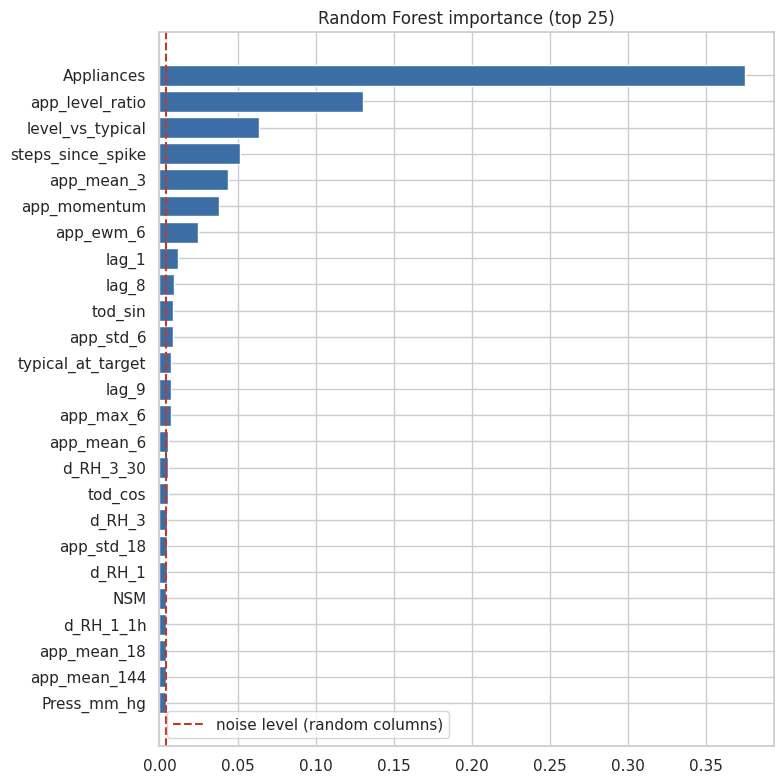

In [ ]:
# 5.2 Importance compared with random noise
probe_cols = ['rv1', 'noise_probe']
forest_sel = make_forest(N_TREES_FAST).fit(X_train_sel[survivors + probe_cols], y_train_sel)
importance = pd.Series(forest_sel.feature_importances_, index=survivors + probe_cols).sort_values(ascending=False)
noise_level = importance[probe_cols].max()
above_noise = [c for c in survivors if importance[c] > noise_level]
print(f'Noise level (best random column): {noise_level:.5f}')
print(f'Features more important than noise: {len(above_noise)} of {len(survivors)}')

top_features = importance.drop(probe_cols).head(25)[::-1]
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(top_features.index, top_features.values, color='#3b6ea5')
ax.axvline(noise_level, color='#c0392b', ls='--', label='noise level (random columns)')
ax.set_title('Random Forest importance (top 25)')
ax.legend()
save_fig('feature_importance')
save_table(importance.rename('importance').to_frame(), 'feature_importance')

In [ ]:
# 5.3 Recursive Feature Elimination (RFE) gives a ranking of the remaining features
rfe_forest = RandomForestRegressor(n_estimators=N_TREES_FAST // 2 + 5, min_samples_leaf=5, max_features=0.5,
                                   n_jobs=-1, random_state=SEED)
rfe = RFE(estimator=rfe_forest, n_features_to_select=10, step=4)
rfe.fit(X_train_sel[above_noise], y_train_sel)

rfe_order = pd.DataFrame({'feature': above_noise, 'rank': rfe.ranking_, 'importance': importance[above_noise].values})
rfe_order = rfe_order.sort_values(['rank', 'importance'], ascending=[True, False]).reset_index(drop=True)
print('Top 15 by RFE:', rfe_order['feature'].head(15).tolist())

Top 15 by RFE: ['Appliances', 'app_level_ratio', 'level_vs_typical', 'steps_since_spike', 'app_mean_3', 'app_momentum', 'app_ewm_6', 'lag_8', 'app_std_18', 'NSM', 'lag_1', 'tod_sin', 'typical_at_target', 'lag_9', 'app_mean_6']


In [ ]:
# 5.4 Compare candidate feature sets on the validation set
candidate_sets = {'All candidates': CANDIDATES,
                  'After correlation filter': survivors,
                  'Above noise level': above_noise}
for k in [40, 30, 20, 15, 10]:
    if k < len(above_noise):
        candidate_sets[f'RFE top {k}'] = rfe_order['feature'].head(k).tolist()

selection_rows = []
for set_name, cols in candidate_sets.items():
    forest = make_forest(N_TREES_FAST).fit(feat.loc[masks['train'], cols], y_train_sel)
    metrics = regression_metrics(y_all[masks['val']], forest.predict(feat.loc[masks['val'], cols]))
    selection_rows.append({'Feature set': set_name, 'n features': len(cols), 'Val MAE': metrics['MAE'],
                           'Val RMSE': metrics['RMSE'], 'Score': validation_score(metrics, persistence_val)})
selection_table = pd.DataFrame(selection_rows).set_index('Feature set').round(4)
save_table(selection_table, 'feature_selection_comparison')
print(selection_table)

# Rule: take the smallest set whose score is within 1% of the best score
best_score = selection_table['Score'].min()
good_enough = selection_table[selection_table['Score'] <= best_score * 1.01]
chosen_name = good_enough['n features'].idxmin()
SELECTED = candidate_sets[chosen_name]
print(f'\nChosen set: "{chosen_name}" with {len(SELECTED)} features')
print(SELECTED)
json.dump(SELECTED, open(MODEL_DIR / 'selected_features.json', 'w'), indent=1)

                          n features  Val MAE  Val RMSE   Score
Feature set                                                    
All candidates                    93  27.9683   58.2971  0.9237
After correlation filter          90  28.1861   58.4604  0.9289
Above noise level                 23  25.4992   56.7966  0.8683
RFE top 20                        20  25.6163   57.3212  0.8741
RFE top 15                        15  25.6947   57.1456  0.8743
RFE top 10                        10  26.1518   58.4029  0.8916

Chosen set: "RFE top 15" with 15 features
['Appliances', 'app_level_ratio', 'level_vs_typical', 'steps_since_spike', 'app_mean_3', 'app_momentum', 'app_ewm_6', 'lag_8', 'app_std_18', 'NSM', 'lag_1', 'tod_sin', 'typical_at_target', 'lag_9', 'app_mean_6']


**Why this selection is reasonable.** The final set is chosen by validation error, and it is the smallest set that stays within 1% of the best score. This keeps the input small (faster training, less overfitting) without losing accuracy. Features that are no better than random noise are removed, and near-duplicates are removed so that the inputs stay independent.

In [ ]:
# 5.5 Which feature groups made it into the final set?
group_map = {'Original sensors': ORIGINAL_COLS, 'Calendar': TIME_COLS, 'Recent history': HISTORY_COLS,
             'Context rolling': CONTEXT_COLS, 'Interactions': INTERACTION_COLS}
group_counts = pd.DataFrame({'selected': {g: len([c for c in cols if c in SELECTED]) for g, cols in group_map.items()},
                             'candidates': {g: len(cols) for g, cols in group_map.items()}})
save_table(group_counts, 'selected_feature_groups')
print(group_counts)
print('\nSelected interaction / context features:', [c for c in SELECTED if c in INTERACTION_COLS + CONTEXT_COLS])

                  selected  candidates
Original sensors         0          25
Calendar                 2          12
Recent history          13          36
Context rolling          0           3
Interactions             0          17

Selected interaction / context features: []


## 6. Scaling and sequence windows
**Scaling choice: standardisation (zero mean, unit variance).** After capping, most features are roughly bell-shaped or bounded, and standardisation is less affected by a few extreme values than Min-Max scaling (Min-Max squeezes most values into a small range when one value is far away). It also works well with the tanh and sigmoid gates inside LSTM and GRU layers. The scaler is **fitted on the training rows only** and then applied to validation and test, so no test information leaks into training.

**Target scaling.** The target is very skewed. We train on one of two versions of it: (a) standardised raw values, or (b) standardised `log(1 + y)`. Predictions are always converted back to Wh before MAE and RMSE are computed.

**Sequence windows.** An LSTM or GRU needs a short "film strip" of the past. For each prediction we give the model the last *W* time steps (for example 24 steps = 4 hours) of all selected features, and it predicts the energy use one step ahead.

In [ ]:
# 6.1 Bundle: selected features, scaler, targets and split masks for a given horizon
def prepare_bundle(horizon):
    """Build the feature table for a horizon, split it in time order and scale it with training statistics."""
    table, _ = build_feature_table(clean, LAGS, horizon)
    split = make_split_masks(table.index, horizon)
    scaler = StandardScaler().fit(table.loc[split['train'], SELECTED])
    return {'horizon': horizon, 'table': table, 'masks': split,
            'X': scaler.transform(table[SELECTED]).astype('float32'),
            'y': table['target'].values.astype('float32'), 'scaler': scaler}


bundle = prepare_bundle(HORIZON)
print('Scaled feature matrix:', bundle['X'].shape)
print('Mean of scaled training features (should be ~0):', float(bundle['X'][bundle['masks']['train']].mean().round(4)))
joblib.dump(bundle['scaler'], MODEL_DIR / 'feature_scaler.joblib')

Scaled feature matrix: (19590, 15)
Mean of scaled training features (should be ~0): 0.0


['/content/models/feature_scaler.joblib']

In [ ]:
# 6.2 Target transformation and window creation
class TargetTransform:
    """Scales the target, optionally after taking log(1 + y). inverse() returns values in Wh."""

    def __init__(self, mode='raw'):
        assert mode in ('raw', 'log')
        self.mode = mode

    def _forward(self, y):
        return np.log1p(y) if self.mode == 'log' else np.asarray(y, dtype='float64')

    def fit(self, y_train):
        z = self._forward(y_train)
        self.mean_, self.std_ = float(z.mean()), float(z.std())
        self.floor_ = float(np.min(y_train))
        return self

    def transform(self, y):
        return ((self._forward(y) - self.mean_) / self.std_).astype('float32')

    def inverse(self, z):
        out = np.asarray(z, dtype='float64').ravel() * self.std_ + self.mean_
        if self.mode == 'log':
            out = np.expm1(out)
        return np.clip(out, self.floor_, None)      # energy use cannot be lower than the lowest value seen in training


def make_windows(X, rows, window):
    """For each row r return the block of the last `window` rows (r-window+1 ... r)."""
    all_windows = sliding_window_view(X, window_shape=window, axis=0)       # (n-window+1, features, window)
    return np.ascontiguousarray(all_windows[rows - (window - 1)].transpose(0, 2, 1))


_data_cache = {}


def get_data(bundle, window, target_mode):
    """Windows and scaled targets for train / validation / test. Cached, because it is used many times."""
    key = (bundle['horizon'], window, target_mode)
    if key in _data_cache:
        return _data_cache[key]
    transform = TargetTransform(target_mode).fit(bundle['y'][bundle['masks']['train']])
    data = {'target_transform': transform}
    for part in ['train', 'val', 'test']:
        rows = np.where(bundle['masks'][part])[0]
        rows = rows[rows >= window - 1]
        data[f'X_{part}'] = make_windows(bundle['X'], rows, window)
        data[f'y_{part}'] = transform.transform(bundle['y'][rows])
        data[f'y_{part}_raw'] = bundle['y'][rows].astype('float64')
        data[f'rows_{part}'] = rows
    _data_cache[key] = data
    return data


demo = get_data(bundle, 24, 'raw')
print('Train windows:', demo['X_train'].shape, '| Val:', demo['X_val'].shape, '| Test:', demo['X_test'].shape)

# Window check: the last step of a window is the row itself, and the first step is 23 rows earlier
r = demo['rows_test'][5]
assert np.allclose(demo['X_test'][5, -1], bundle['X'][r]) and np.allclose(demo['X_test'][5, 0], bundle['X'][r - 23])
print('Window check passed.')

Train windows: (13273, 24, 15) | Val: (2346, 24, 15) | Test: (3947, 24, 15)
Window check passed.


## 7. Baseline models
Baselines tell us what "good" looks like. If a deep model cannot beat a simple one, it is not worth its complexity. All baselines use the same selected features and the same train / validation / test rows.
- **Persistence:** predict that the next 10 minutes equal the current reading. This is the standard "do nothing smart" benchmark for forecasting.
- **1-hour moving average:** predict the average of the last 6 readings.
- **Linear Regression** and **Random Forest** (the baselines required by the assessment).
- **Gradient Boosting:** a strong tree-based model, as an extra reference.
- **Log-target versions** of Random Forest and Gradient Boosting. The neural networks will also be tested with a log-transformed target (section 9), so the trees get the same chance. This keeps the comparison fair.

In [ ]:
# 7.1 Train and evaluate the baselines
def make_boosting():
    """Gradient Boosting with fixed, sensible settings."""
    return HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_leaf_nodes=31,
                                         l2_regularization=1.0, random_state=SEED)


def run_baselines(bundle):
    """Fit every baseline. Returns the metric table and the validation and test predictions of each model."""
    table, split, y, X = bundle['table'], bundle['masks'], bundle['y'], bundle['X']
    val_preds, test_preds = {}, {}

    val_preds['Persistence (last value)'] = table.loc[split['val'], TARGET].values
    test_preds['Persistence (last value)'] = table.loc[split['test'], TARGET].values
    val_preds['Moving average (1 hour)'] = table.loc[split['val'], 'app_mean_6'].values
    test_preds['Moving average (1 hour)'] = table.loc[split['test'], 'app_mean_6'].values

    tabular_models = [('Linear Regression', LinearRegression(), 'raw'),
                      ('Random Forest', make_forest(N_TREES), 'raw'),
                      ('Random Forest (log target)', make_forest(N_TREES), 'log'),
                      ('Gradient Boosting', make_boosting(), 'raw'),
                      ('Gradient Boosting (log target)', make_boosting(), 'log')]
    for name, model, target_mode in tabular_models:
        transform = TargetTransform(target_mode).fit(y[split['train']])
        model.fit(X[split['train']], transform.transform(y[split['train']]))
        val_preds[name] = transform.inverse(model.predict(X[split['val']]))
        test_preds[name] = transform.inverse(model.predict(X[split['test']]))

    rows = []
    for name in val_preds:
        for part, preds in [('Validation', val_preds), ('Test', test_preds)]:
            mask = split['val'] if part == 'Validation' else split['test']
            rows.append({'Model': name, 'Set': part, **regression_metrics(y[mask], preds[name])})
    return pd.DataFrame(rows), val_preds, test_preds


baseline_results, baseline_val_preds, baseline_test_preds = run_baselines(bundle)
save_table(baseline_results.round(4), 'baseline_results')
baseline_results[baseline_results['Set'] == 'Test'].set_index('Model').drop(columns='Set').round(3)

,MAE,RMSE,MAPE %,R2
Model,,,,
Persistence (last value),26.651,66.438,21.936,0.467
Moving average (1 hour),34.296,75.528,28.917,0.312
Linear Regression,27.283,59.733,25.151,0.569
Random Forest,25.676,58.124,23.132,0.592
Random Forest (log target),23.687,58.884,19.132,0.582
Gradient Boosting,25.279,58.830,22.510,0.582
Gradient Boosting (log target),23.635,58.992,19.134,0.580


## 8. Deep learning model design
**Architectures compared**

| Name | Idea |
|---|---|
| MLP | Flattens the window and uses ordinary dense layers. Shows whether "time order" modelling is needed at all. |
| LSTM | Recurrent layers with memory gates; good at keeping information over time. |
| GRU | A lighter version of the LSTM with fewer parameters; often as good on small data. |
| CNN-LSTM | A 1-D convolution first finds short local patterns (for example a quick rise in humidity), then an LSTM reads them in order. |

**Common design choices and reasons**
- **Hidden activation:** `tanh` inside LSTM/GRU (the standard choice; it keeps values between -1 and 1 and allows the fast GPU kernels), `ReLU` in the convolution and dense layers (simple, avoids vanishing gradients).
- **Output layer:** one neuron with a linear activation, because we predict a number (regression).
- **Loss:** Mean Squared Error (MSE) is the default regression loss and matches RMSE. Huber loss is tested as well, because it is less sensitive to the large spikes.
- **Optimiser:** Adam (adaptive learning rate, works well without much tuning) and RMSprop are compared.
- **Overfitting control:** dropout between layers, an L2 weight penalty, early stopping on validation loss, and learning-rate reduction when progress stalls.
- **Training length:** at most 50 epochs; early stopping picks the real number.

In [ ]:
# 8.1 Model builder
def build_model(arch, window, n_features, units=64, n_layers=2, dropout=0.2, l2=1e-5,
                dense_units=32, lr=1e-3, optimizer='adam', loss='mse'):
    """Create and compile a Keras model. arch is one of: mlp, lstm, gru, cnn_lstm."""
    penalty = regularizers.l2(l2) if l2 else None
    model = keras.Sequential(name=f'{arch}_model')
    model.add(keras.Input(shape=(window, n_features)))

    if arch == 'mlp':
        model.add(layers.Flatten())
        for _ in range(n_layers):
            model.add(layers.Dense(units, activation='relu', kernel_regularizer=penalty))
            model.add(layers.Dropout(dropout))
    else:
        if arch == 'cnn_lstm':
            model.add(layers.Conv1D(filters=units, kernel_size=3, padding='causal', activation='relu',
                                    kernel_regularizer=penalty))
            model.add(layers.Dropout(dropout))
        recurrent_layer = layers.GRU if arch == 'gru' else layers.LSTM
        for i in range(n_layers):
            is_last_layer = (i == n_layers - 1)
            model.add(recurrent_layer(units, activation='tanh', return_sequences=not is_last_layer,
                                      kernel_regularizer=penalty))
            model.add(layers.Dropout(dropout))

    model.add(layers.Dense(dense_units, activation='relu', kernel_regularizer=penalty))
    model.add(layers.Dense(1, activation='linear'))

    if optimizer == 'rmsprop':
        optimizer_object = keras.optimizers.RMSprop(learning_rate=lr)
    else:
        optimizer_object = keras.optimizers.Adam(learning_rate=lr)
    loss_function = keras.losses.Huber(delta=1.0) if loss == 'huber' else 'mse'
    model.compile(optimizer=optimizer_object, loss=loss_function, metrics=['mae'])
    return model


# Starting point for every comparison; the arch is filled in later
DEFAULT_CFG = dict(arch='gru', window=24, units=64, n_layers=2, dropout=0.2, l2=1e-5, dense_units=32,
                   lr=1e-3, batch_size=64, optimizer='adam', loss='mse', target_mode='raw')

build_model('lstm', 24, len(SELECTED)).summary()

Model: "lstm_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 24, 64)         │        20,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 55,617 (217.25 KB)

 Trainable params: 55,617 (217.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# 8.2 Helpers for training and scoring
experiment_log = []                      # every trained model is noted here and saved at the end


def train_model(cfg, bundle, seed=SEED, max_epochs=MAX_EPOCHS, keep_model=False):
    """Train one network with early stopping. Returns its history and its predictions in Wh."""
    keras.backend.clear_session()
    set_all_seeds(seed)
    data = get_data(bundle, cfg['window'], cfg['target_mode'])
    model = build_model(cfg['arch'], cfg['window'], len(SELECTED), cfg['units'], cfg['n_layers'], cfg['dropout'],
                        cfg['l2'], cfg['dense_units'], cfg['lr'], cfg['optimizer'], cfg['loss'])
    stoppers = [callbacks.EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True),
                callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-5)]
    start = time.time()
    history = model.fit(data['X_train'], data['y_train'], validation_data=(data['X_val'], data['y_val']),
                        epochs=max_epochs, batch_size=cfg['batch_size'], callbacks=stoppers,
                        shuffle=True, verbose=0)

    run = {'seed': seed, 'history': history.history, 'seconds': time.time() - start,
           'epochs_run': len(history.history['loss']),
           'best_epoch': int(np.argmin(history.history['val_loss'])) + 1,
           'params': int(model.count_params())}
    for part in ['val', 'test']:
        predictions = data['target_transform'].inverse(model.predict(data[f'X_{part}'], batch_size=512, verbose=0))
        run[f'pred_{part}'] = predictions
        run[f'metrics_{part}'] = regression_metrics(data[f'y_{part}_raw'], predictions)
    run['val_score'] = validation_score(run['metrics_val'], persistence_val)
    if keep_model:
        run['model'] = model
    return run


def note_run(stage, name, cfg, run):
    """Add one trained network to the experiment log."""
    experiment_log.append({'stage': stage, 'name': name, **cfg, 'seed': run['seed'],
                           'val_MAE': run['metrics_val']['MAE'], 'val_RMSE': run['metrics_val']['RMSE'],
                           'val_score': run['val_score'],
                           'test_MAE': run['metrics_test']['MAE'], 'test_RMSE': run['metrics_test']['RMSE'],
                           'epochs_run': run['epochs_run'], 'best_epoch': run['best_epoch'],
                           'params': run['params'], 'minutes': round(run['seconds'] / 60, 2)})


def train_with_seeds(cfg, bundle, seeds, stage, name):
    """Train the same configuration with several seeds. Returns the list of runs."""
    runs = []
    for seed in seeds:
        run = train_model(cfg, bundle, seed=seed)
        note_run(stage, name, cfg, run)
        runs.append(run)
    return runs


def ensemble_predictions(runs):
    """Average the predictions of several runs (validation and test)."""
    return (np.mean([r['pred_val'] for r in runs], axis=0), np.mean([r['pred_test'] for r in runs], axis=0))

## 9. Model comparison and optimisation
Every choice is made on the **validation set only**. Test numbers are logged for the report but never used to decide anything.

**The score used for decisions.** MAE and RMSE are both important, but they point in different directions for this data: models trained on log-transformed values or with Huber loss get a lower MAE, while models trained with squared error get a lower RMSE (they pay more attention to the big spikes). To treat both fairly we use one balanced score: MAE and RMSE are each divided by the error of the persistence baseline on the same data, and the two ratios are averaged. A score of 1.0 means "as good as persistence"; lower is better.

Steps:
1. **Architecture:** MLP, LSTM, GRU and CNN-LSTM with default settings, each with two seeds.
2. **Random search** over the main hyperparameters, including optimiser, loss and target transformation.
3. **Confirmation:** the best candidates are trained again with three new seeds, because one run can be lucky.
4. **Dropout sweep** on the winner (different dropout rates, as asked in the assessment).
5. **Final models:** five-seed ensembles, and a blend of the best "raw target" model and the best "log target" model.

In [ ]:
# 9.1 Step 1: architecture comparison
architecture_rows = []
for arch in ['mlp', 'lstm', 'gru', 'cnn_lstm']:
    cfg = {**DEFAULT_CFG, 'arch': arch}
    runs = train_with_seeds(cfg, bundle, ARCH_SEEDS, '1-architecture', arch)
    architecture_rows.append({'Architecture': arch, 'Parameters': runs[0]['params'],
                              'Val MAE': np.mean([r['metrics_val']['MAE'] for r in runs]),
                              'Val RMSE': np.mean([r['metrics_val']['RMSE'] for r in runs]),
                              'Score': np.mean([r['val_score'] for r in runs]),
                              'Epochs run': np.mean([r['epochs_run'] for r in runs]),
                              'Test MAE': np.mean([r['metrics_test']['MAE'] for r in runs]),
                              'Test RMSE': np.mean([r['metrics_test']['RMSE'] for r in runs])})
    print(f"{arch:9s} val MAE {architecture_rows[-1]['Val MAE']:.2f} | val RMSE {architecture_rows[-1]['Val RMSE']:.2f} | "
          f"score {architecture_rows[-1]['Score']:.4f}")

architecture_table = pd.DataFrame(architecture_rows).set_index('Architecture').round(3)
save_table(architecture_table, 'architecture_comparison')
BEST_ARCH = architecture_table['Score'].idxmin()
BASE_CFG = {**DEFAULT_CFG, 'arch': BEST_ARCH}
print('\nBest architecture on validation data:', BEST_ARCH)
architecture_table

mlp       val MAE 28.09 | val RMSE 60.85 | score 0.9441
lstm      val MAE 26.59 | val RMSE 58.22 | score 0.8983
gru       val MAE 26.39 | val RMSE 58.28 | score 0.8950
cnn_lstm  val MAE 26.25 | val RMSE 57.99 | score 0.8905

Best architecture on validation data: cnn_lstm


,Parameters,Val MAE,Val RMSE,Score,Epochs run,Test MAE,Test RMSE
Architecture,,,,,,,
mlp,29377,28.085,60.853,0.944,26.0,27.870,59.743
lstm,55617,26.593,58.221,0.898,24.5,26.460,58.089
gru,42625,26.389,58.275,0.895,24.0,26.428,58.216
cnn_lstm,71105,26.254,57.994,0.891,27.5,26.678,58.488


In [ ]:
# 9.2 Step 2: random search
SEARCH_SPACE = dict(window=[6, 12, 24, 36, 48], units=[32, 64, 128], n_layers=[1, 2, 3],
                    dropout=[0.1, 0.2, 0.3, 0.4], l2=[0, 1e-5, 1e-4], dense_units=[16, 32, 64],
                    lr=[3e-4, 1e-3, 3e-3], batch_size=[64, 128, 256],
                    optimizer=['adam', 'rmsprop'], loss=['mse', 'huber'])
search_rng = np.random.default_rng(SEED)


def sample_configuration(trial_number):
    """Pick random settings. The target transformation alternates (raw, log, raw, ...) so both are tested equally."""
    settings = {name: options[int(search_rng.integers(len(options)))] for name, options in SEARCH_SPACE.items()}
    settings['target_mode'] = 'raw' if trial_number % 2 == 0 else 'log'
    return {**BASE_CFG, **settings}


trials = [BASE_CFG]                                   # trial 0 = the default, so the search can never end up worse
seen = {tuple(sorted(BASE_CFG.items()))}
while len(trials) < N_TRIALS:
    cfg = sample_configuration(len(trials))
    if tuple(sorted(cfg.items())) not in seen:
        seen.add(tuple(sorted(cfg.items())))
        trials.append(cfg)

search_results = []
for number, cfg in enumerate(trials):
    run = train_model(cfg, bundle, seed=SEED)
    note_run('2-random-search', f'trial_{number}', cfg, run)
    search_results.append((number, cfg, run))
    print(f"trial {number:2d} | val MAE {run['metrics_val']['MAE']:.2f} RMSE {run['metrics_val']['RMSE']:.2f} "
          f"score {run['val_score']:.4f} | {cfg['optimizer']:7s} {cfg['loss']:5s} {cfg['target_mode']:3s} "
          f"win {cfg['window']:2d} units {cfg['units']:3d} layers {cfg['n_layers']} drop {cfg['dropout']} lr {cfg['lr']}")

search_table = pd.DataFrame([e for e in experiment_log if e['stage'] == '2-random-search']).sort_values('val_score')
save_table(search_table.set_index('name').round(4), 'random_search_results')

# Which settings seem to matter? Average score by choice (rough guide only: few trials)
factor_rows = []
for factor in ['target_mode', 'loss', 'optimizer']:
    for value, group in search_table.groupby(factor):
        factor_rows.append({'setting': factor, 'value': value, 'trials': len(group),
                            'mean val MAE': group['val_MAE'].mean(), 'mean val RMSE': group['val_RMSE'].mean(),
                            'mean score': group['val_score'].mean()})
factor_table = pd.DataFrame(factor_rows).set_index(['setting', 'value']).round(3)
save_table(factor_table, 'search_factor_summary')
factor_table

trial  0 | val MAE 25.68 RMSE 57.50 score 0.8766 | adam    mse   raw win 24 units  64 layers 2 drop 0.2 lr 0.001
trial  1 | val MAE 24.83 RMSE 60.91 score 0.8856 | adam    mse   log win  6 units 128 layers 2 drop 0.2 lr 0.0003
trial  2 | val MAE 25.56 RMSE 58.01 score 0.8781 | rmsprop mse   raw win 24 units 128 layers 3 drop 0.4 lr 0.001
trial  3 | val MAE 25.11 RMSE 63.03 score 0.9058 | rmsprop mse   log win 24 units  64 layers 1 drop 0.4 lr 0.001
trial  4 | val MAE 24.26 RMSE 59.15 score 0.8627 | adam    huber raw win 24 units  32 layers 1 drop 0.3 lr 0.003
trial  5 | val MAE 24.10 RMSE 60.40 score 0.8686 | rmsprop huber log win  6 units 128 layers 3 drop 0.2 lr 0.001
trial  6 | val MAE 24.36 RMSE 59.64 score 0.8680 | rmsprop huber raw win 36 units  32 layers 2 drop 0.2 lr 0.001
trial  7 | val MAE 23.81 RMSE 60.06 score 0.8610 | adam    mse   log win 48 units 128 layers 2 drop 0.4 lr 0.003
trial  8 | val MAE 24.61 RMSE 59.92 score 0.8746 | rmsprop huber raw win 36 units  32 layers 2 

trials  mean val MAE  mean val RMSE  mean score
setting     value                                                   
target_mode log           8        24.531         61.481       0.884
            raw           8        25.217         58.756       0.877
loss        huber         7        24.418         60.498       0.875
            mse           9        25.229         59.823       0.885
optimizer   adam          7        24.766         59.110       0.872
            rmsprop       9        24.958         60.903       0.888

In [ ]:
# 9.3 Step 3: confirm the best candidates of each target family with new seeds
confirm_rows, confirmed = [], []
for family in ['raw', 'log']:
    family_trials = sorted([t for t in search_results if t[1]['target_mode'] == family],
                           key=lambda t: t[2]['val_score'])[:CONFIRM_PER_FAMILY]
    for number, cfg, _ in family_trials:
        runs = train_with_seeds(cfg, bundle, CONFIRM_SEEDS, '3-confirmation', f'trial_{number}')
        scores = [r['val_score'] for r in runs]
        confirmed.append({'family': family, 'trial': number, 'cfg': cfg, 'mean_score': np.mean(scores)})
        confirm_rows.append({'Trial': number, 'Target': family, 'Optimiser': cfg['optimizer'], 'Loss': cfg['loss'],
                             'Window': cfg['window'], 'Units': cfg['units'], 'Layers': cfg['n_layers'],
                             'Dropout': cfg['dropout'], 'Search score': search_results[number][2]['val_score'],
                             'Mean score (new seeds)': np.mean(scores), 'Std': np.std(scores),
                             'Mean val MAE': np.mean([r['metrics_val']['MAE'] for r in runs]),
                             'Mean val RMSE': np.mean([r['metrics_val']['RMSE'] for r in runs])})
confirm_table = pd.DataFrame(confirm_rows).set_index('Trial').round(4)
save_table(confirm_table, 'confirmation_results')

best_by_family = {}
for family in ['raw', 'log']:
    candidates_in_family = [c for c in confirmed if c['family'] == family]
    best_by_family[family] = min(candidates_in_family, key=lambda c: c['mean_score'])

MAIN_FAMILY = min(best_by_family, key=lambda f: best_by_family[f]['mean_score'])
COMPANION_FAMILY = 'log' if MAIN_FAMILY == 'raw' else 'raw'
MAIN_CFG = dict(best_by_family[MAIN_FAMILY]['cfg'])
COMPANION_CFG = dict(best_by_family[COMPANION_FAMILY]['cfg'])
print(f"Main model: trial {best_by_family[MAIN_FAMILY]['trial']} ({MAIN_FAMILY} target), "
      f"score {best_by_family[MAIN_FAMILY]['mean_score']:.4f}")
print(f"Companion model: trial {best_by_family[COMPANION_FAMILY]['trial']} ({COMPANION_FAMILY} target), "
      f"score {best_by_family[COMPANION_FAMILY]['mean_score']:.4f}")
confirm_table

Main model: trial 4 (raw target), score 0.8610
Companion model: trial 7 (log target), score 0.8626


,Target,Optimiser,Loss,Window,Units,Layers,Dropout,Search score,Mean score (new seeds),Std,Mean val MAE,Mean val RMSE
Trial,,,,,,,,,,,,
4,raw,adam,huber,24,32,1,0.3,0.8627,0.8610,0.0056,24.1374,59.2314
6,raw,rmsprop,huber,36,32,2,0.2,0.8680,0.8659,0.0039,24.4735,59.0651
7,log,adam,mse,48,128,2,0.4,0.8610,0.8626,0.0038,23.9215,60.0002
11,log,adam,huber,48,32,3,0.1,0.8636,0.8720,0.0057,24.0198,61.0630


In [ ]:
# 9.4 Step 4: dropout sweep for the main model
sweep_rates = sorted(set(DROPOUT_RATES) | {MAIN_CFG['dropout']})      # always include the rate found by the search
sweep_rows = []
for rate in sweep_rates:
    cfg = {**MAIN_CFG, 'dropout': rate}
    runs = train_with_seeds(cfg, bundle, SWEEP_SEEDS, '4-dropout-sweep', f'dropout_{rate}')
    sweep_rows.append({'Dropout': rate, 'Val MAE': np.mean([r['metrics_val']['MAE'] for r in runs]),
                       'Val RMSE': np.mean([r['metrics_val']['RMSE'] for r in runs]),
                       'Score': np.mean([r['val_score'] for r in runs]),
                       'Best epoch': np.mean([r['best_epoch'] for r in runs])})
    print(f"dropout {rate}: score {sweep_rows[-1]['Score']:.4f}")

dropout_table = pd.DataFrame(sweep_rows).set_index('Dropout').round(4)
save_table(dropout_table, 'dropout_sweep')

# keep the dropout from the search unless another rate is clearly better (more than 1% lower score)
current_score = dropout_table.loc[MAIN_CFG['dropout'], 'Score']
best_rate = float(dropout_table['Score'].idxmin())
if dropout_table.loc[best_rate, 'Score'] < current_score * 0.99:
    MAIN_CFG['dropout'] = best_rate
print('Dropout of the main model:', MAIN_CFG['dropout'])
print('Main configuration:', MAIN_CFG)
dropout_table

dropout 0.0: score 0.8704
dropout 0.1: score 0.8539
dropout 0.2: score 0.8570
dropout 0.3: score 0.8643
dropout 0.5: score 0.8753
Dropout of the main model: 0.1
Main configuration: {'arch': 'cnn_lstm', 'window': 24, 'units': 32, 'n_layers': 1, 'dropout': 0.1, 'l2': 0.0001, 'dense_units': 16, 'lr': 0.003, 'batch_size': 256, 'optimizer': 'adam', 'loss': 'huber', 'target_mode': 'raw'}


,Val MAE,Val RMSE,Score,Best epoch
Dropout,,,,
0.0,24.7930,58.8811,0.8704,17.0
0.1,24.1500,58.2034,0.8539,24.5
0.2,24.1997,58.5095,0.8570,26.5
0.3,24.2896,59.3100,0.8643,31.0
0.5,24.3872,60.5988,0.8753,39.0


## 10. Final models and test evaluation
We now train the final networks with five seeds each. A neural network starts from random weights, so a single run can be a little lucky or unlucky; the average of five runs is more stable.
- **Default model** (best architecture, default settings): trained the same way, so that "before" and "after" optimisation can be compared fairly.
- **Main model** and **companion model**: the best configurations from the search (one with a raw target, one with a log target).
- **Final blend:** `w x main + (1 - w) x companion`. The weight `w` is chosen on the validation set only.

The test set is used here for the first time for a final judgement.

In [ ]:
# 10.1 Train the default, main and companion ensembles
def train_final_runs(cfg, label):
    """Train the final ensemble of one configuration and keep the models in memory."""
    runs = []
    for seed in FINAL_SEEDS:
        run = train_model(cfg, bundle, seed=seed, keep_model=True)
        note_run('5-final', label, cfg, run)
        runs.append(run)
        print(f"{label:10s} seed {seed:5d} | val MAE {run['metrics_val']['MAE']:.2f} RMSE {run['metrics_val']['RMSE']:.2f} | "
              f"test MAE {run['metrics_test']['MAE']:.2f} RMSE {run['metrics_test']['RMSE']:.2f} | "
              f"best epoch {run['best_epoch']} of {run['epochs_run']}")
    return runs


default_runs = train_final_runs(BASE_CFG, 'default')
main_runs = train_final_runs(MAIN_CFG, 'main')
companion_runs = train_final_runs(COMPANION_CFG, 'companion')

# all networks must be evaluated on exactly the same rows as the baselines
final_data = get_data(bundle, MAIN_CFG['window'], MAIN_CFG['target_mode'])
y_val_true, y_test_true = final_data['y_val_raw'], final_data['y_test_raw']
assert len(y_val_true) == int(bundle['masks']['val'].sum()) and len(y_test_true) == int(bundle['masks']['test'].sum())

default    seed    42 | val MAE 25.96 RMSE 57.52 | test MAE 26.81 RMSE 58.96 | best epoch 16 of 24
default    seed     7 | val MAE 25.35 RMSE 58.03 | test MAE 25.07 RMSE 57.47 | best epoch 21 of 29
default    seed  2024 | val MAE 25.29 RMSE 58.20 | test MAE 25.23 RMSE 57.75 | best epoch 33 of 41
default    seed    11 | val MAE 24.95 RMSE 57.91 | test MAE 25.64 RMSE 57.60 | best epoch 24 of 32
default    seed    99 | val MAE 25.48 RMSE 57.58 | test MAE 25.88 RMSE 58.33 | best epoch 21 of 29
main       seed    42 | val MAE 24.07 RMSE 59.00 | test MAE 23.56 RMSE 57.28 | best epoch 23 of 31
main       seed     7 | val MAE 23.90 RMSE 58.90 | test MAE 23.62 RMSE 57.21 | best epoch 27 of 35
main       seed  2024 | val MAE 23.77 RMSE 58.32 | test MAE 23.82 RMSE 57.95 | best epoch 41 of 49
main       seed    11 | val MAE 24.21 RMSE 58.99 | test MAE 23.81 RMSE 57.40 | best epoch 27 of 35
main       seed    99 | val MAE 24.18 RMSE 58.49 | test MAE 24.26 RMSE 57.64 | best epoch 16 of 24
companion 

In [ ]:
# 10.2 Blend the main and the companion model (weight chosen on validation data only)
main_val, main_test = ensemble_predictions(main_runs)
companion_val, companion_test = ensemble_predictions(companion_runs)

weight_rows = []
for w in np.linspace(0, 1, 21):
    blended_val = w * main_val + (1 - w) * companion_val
    weight_rows.append({'weight of main model': round(w, 2),
                        'val score': validation_score(regression_metrics(y_val_true, blended_val), persistence_val)})
weight_table = pd.DataFrame(weight_rows).set_index('weight of main model').round(4)
save_table(weight_table, 'blend_weight_search')
BLEND_WEIGHT = float(weight_table['val score'].idxmin())
blend_val = BLEND_WEIGHT * main_val + (1 - BLEND_WEIGHT) * companion_val
blend_test = BLEND_WEIGHT * main_test + (1 - BLEND_WEIGHT) * companion_test
print(f'Best weight of the main model on validation data: {BLEND_WEIGHT:.2f}')

# Why blending can help: do the two models make different mistakes?
error_correlation = np.corrcoef(y_test_true - main_test, y_test_true - companion_test)[0, 1]
print(f'Correlation of the test errors of the two models: {error_correlation:.3f} (lower = more useful to blend)')

Best weight of the main model on validation data: 0.65
Correlation of the test errors of the two models: 0.969 (lower = more useful to blend)


In [ ]:
# 10.3 Results table: baselines and deep learning models
arch_label = BEST_ARCH.upper().replace('_', '-')
default_val, default_test = ensemble_predictions(default_runs)

val_predictions = dict(baseline_val_preds)
test_predictions = dict(baseline_test_preds)
neural_models = {
    f'{arch_label} default settings (single run)': (default_runs[0]['pred_val'], default_runs[0]['pred_test']),
    f'{arch_label} default settings ({len(FINAL_SEEDS)}-run average)': (default_val, default_test),
    f'{arch_label} tuned main model (single run)': (main_runs[0]['pred_val'], main_runs[0]['pred_test']),
    f'{arch_label} tuned main model ({len(FINAL_SEEDS)}-run average)': (main_val, main_test),
    f'{arch_label} companion model ({len(FINAL_SEEDS)}-run average)': (companion_val, companion_test),
    f'{arch_label} FINAL BLEND (main + companion)': (blend_val, blend_test)}
for name, (v, t) in neural_models.items():
    val_predictions[name], test_predictions[name] = v, t
FINAL_NAME = f'{arch_label} FINAL BLEND (main + companion)'

rows = []
for name in val_predictions:
    mv = regression_metrics(y_val_true, val_predictions[name])
    mt = regression_metrics(y_test_true, test_predictions[name])
    rows.append({'Model': name, 'Type': 'Deep learning' if name in neural_models else 'Baseline',
                 'Val MAE': mv['MAE'], 'Val RMSE': mv['RMSE'], 'Val score': validation_score(mv, persistence_val),
                 'Test MAE': mt['MAE'], 'Test RMSE': mt['RMSE'], 'Test MAPE %': mt['MAPE %'], 'Test R2': mt['R2']})
results = pd.DataFrame(rows).set_index('Model').round(3)
save_table(results, 'final_results')
results

,Type,Val MAE,Val RMSE,Val score,Test MAE,Test RMSE,Test MAPE %,Test R2
Model,,,,,,,,
Persistence (last value),Baseline,27.587,69.927,1.000,26.651,66.438,21.936,0.467
Moving average (1 hour),Baseline,37.798,83.447,1.282,34.296,75.528,28.917,0.312
Linear Regression,Baseline,27.930,62.639,0.954,27.283,59.733,25.151,0.569
Random Forest,Baseline,25.676,57.270,0.875,25.676,58.124,23.132,0.592
Random Forest (log target),Baseline,23.762,59.025,0.853,23.687,58.884,19.132,0.582
Gradient Boosting,Baseline,25.316,57.876,0.873,25.279,58.830,22.510,0.582
Gradient Boosting (log target),Baseline,23.805,58.459,0.849,23.635,58.992,19.134,0.580
CNN-LSTM default settings (single run),Deep learning,25.962,57.523,0.882,26.810,58.956,24.261,0.581
CNN-LSTM default settings (5-run average),Deep learning,24.862,56.876,0.857,25.171,57.041,22.688,0.607


In [ ]:
# 10.4 Before and after optimisation (the effect of tuning is separated from the effect of averaging)
steps = {'1. Default settings, one run': neural_models[f'{arch_label} default settings (single run)'],
         f'2. Default settings, {len(FINAL_SEEDS)}-run average': neural_models[f'{arch_label} default settings ({len(FINAL_SEEDS)}-run average)'],
         '3. Tuned main model, one run': neural_models[f'{arch_label} tuned main model (single run)'],
         f'4. Tuned main model, {len(FINAL_SEEDS)}-run average': neural_models[f'{arch_label} tuned main model ({len(FINAL_SEEDS)}-run average)'],
         '5. Final blend (main + companion)': neural_models[FINAL_NAME]}
optimisation_rows = []
for step, (v, t) in steps.items():
    mv, mt = regression_metrics(y_val_true, v), regression_metrics(y_test_true, t)
    optimisation_rows.append({'Step': step, 'Val MAE': mv['MAE'], 'Val RMSE': mv['RMSE'], 'Test MAE': mt['MAE'],
                              'Test RMSE': mt['RMSE'], 'Test MAPE %': mt['MAPE %'], 'Test R2': mt['R2']})
optimisation_table = pd.DataFrame(optimisation_rows).set_index('Step').round(3)
save_table(optimisation_table, 'optimisation_before_after')
optimisation_table

,Val MAE,Val RMSE,Test MAE,Test RMSE,Test MAPE %,Test R2
Step,,,,,,
"1. Default settings, one run",25.962,57.523,26.810,58.956,24.261,0.581
"2. Default settings, 5-run average",24.862,56.876,25.171,57.041,22.688,0.607
"3. Tuned main model, one run",24.074,59.002,23.562,57.279,20.007,0.604
"4. Tuned main model, 5-run average",23.640,58.166,23.433,56.841,20.002,0.610
5. Final blend (main + companion),23.376,58.194,23.150,56.522,19.570,0.615


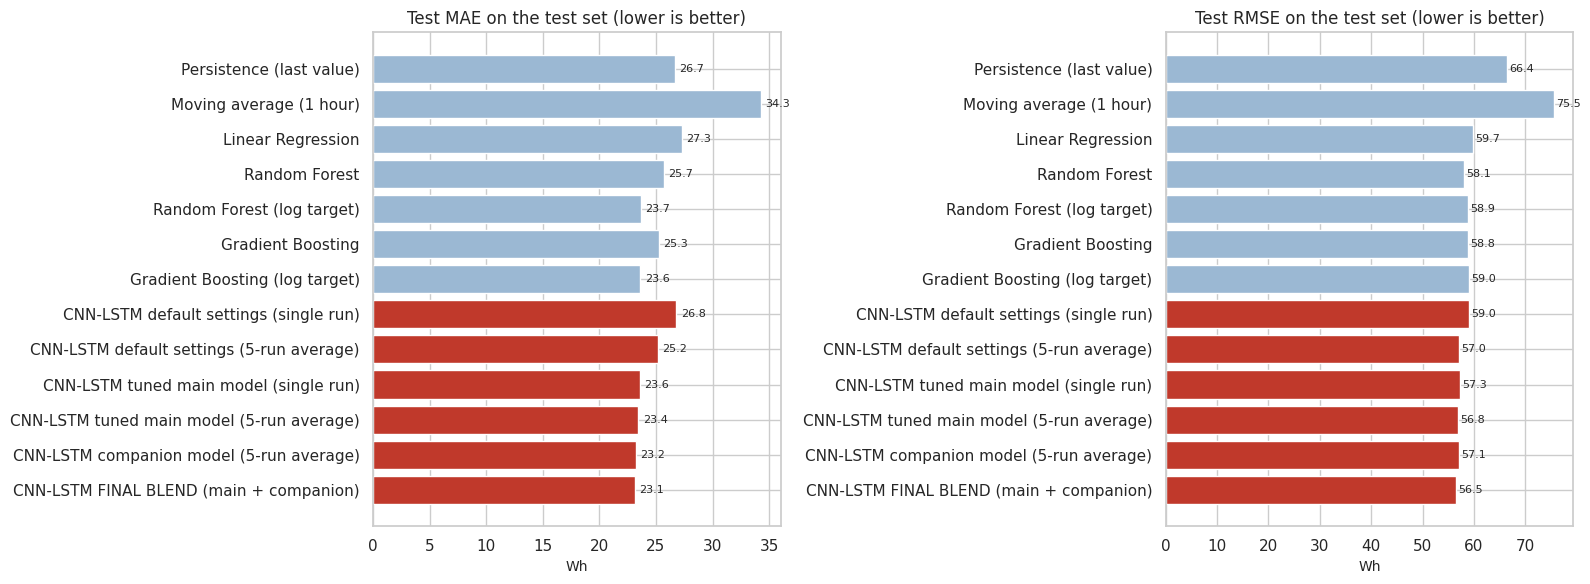

In [ ]:
# 10.5 Architecture and optimisation charts
plot_df = results[['Test MAE', 'Test RMSE']]
bar_colors = ['#c0392b' if t == 'Deep learning' else '#9bb8d3' for t in results['Type']]
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, col in zip(axes, ['Test MAE', 'Test RMSE']):
    ax.barh(plot_df.index[::-1], plot_df[col][::-1], color=bar_colors[::-1])
    ax.set_title(f'{col} on the test set (lower is better)')
    ax.set_xlabel('Wh')
    for i, v in enumerate(plot_df[col][::-1]):
        ax.text(v + 0.4, i, f'{v:.1f}', va='center', fontsize=8)
save_fig('results_metric_comparison')

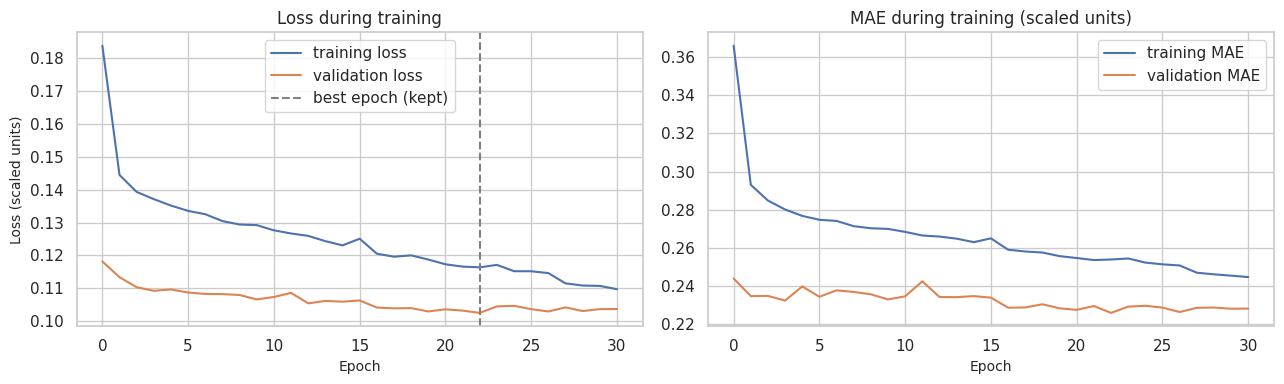

In [ ]:
# 10.6 Training curves of the main model (first seed)
history = main_runs[0]['history']
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history['loss'], label='training loss')
axes[0].plot(history['val_loss'], label='validation loss')
axes[0].axvline(main_runs[0]['best_epoch'] - 1, color='grey', ls='--', label='best epoch (kept)')
axes[0].set_title('Loss during training')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss (scaled units)')
axes[0].legend()
if 'mae' in history:
    axes[1].plot(history['mae'], label='training MAE')
    axes[1].plot(history['val_mae'], label='validation MAE')
    axes[1].set_title('MAE during training (scaled units)')
    axes[1].set_xlabel('Epoch')
    axes[1].legend()
save_fig('training_curves')

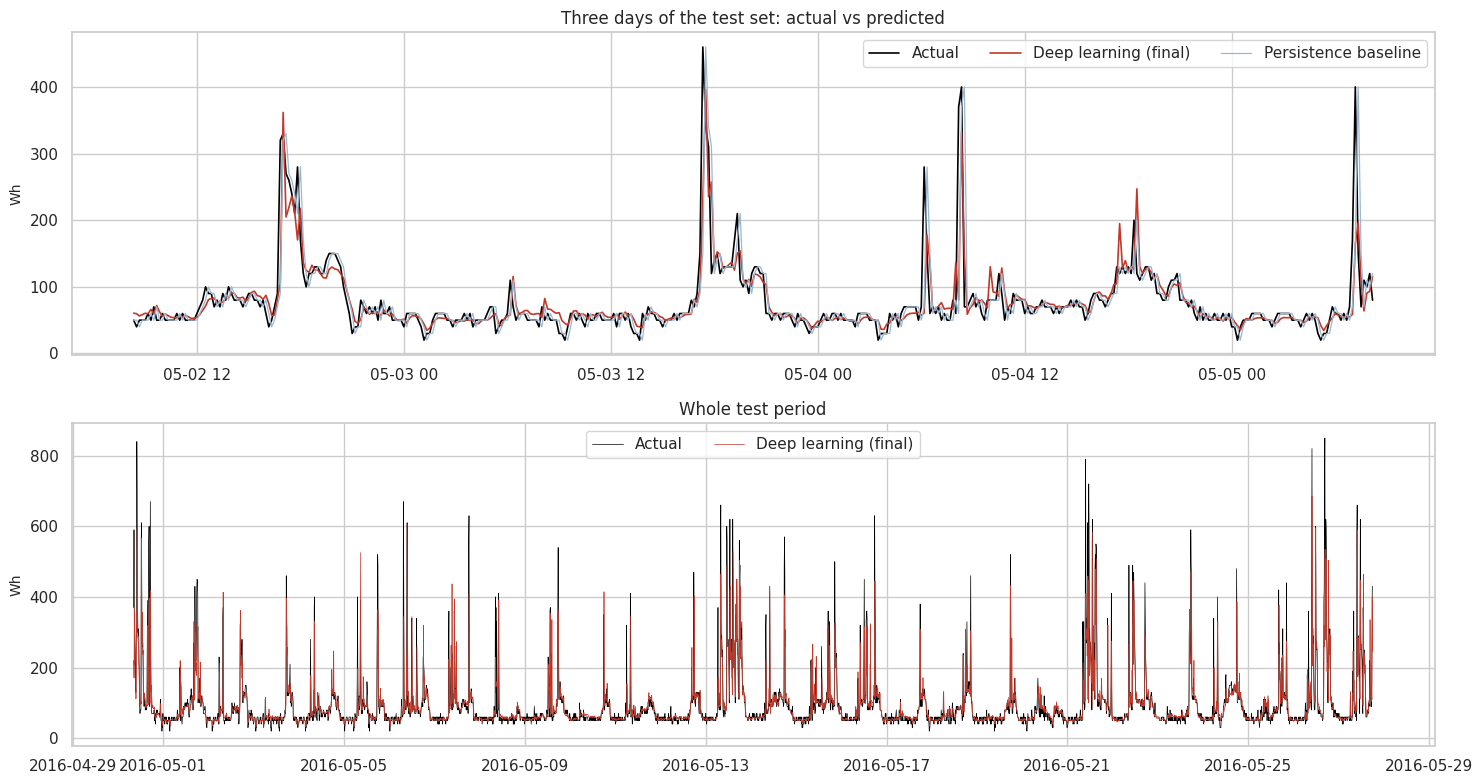

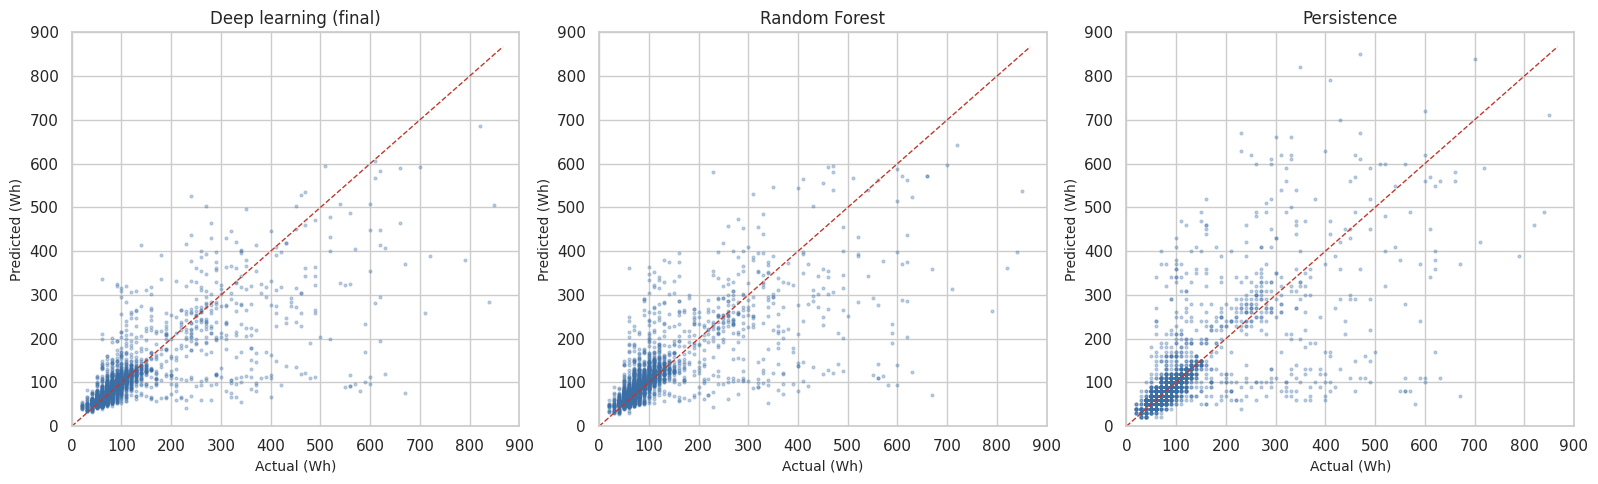

In [ ]:
# 10.7 Predicted vs actual (final blend)
final_test = test_predictions[FINAL_NAME]
persist_test = test_predictions['Persistence (last value)']
forest_test = test_predictions['Random Forest']
test_times = bundle['table'].index[final_data['rows_test']] + pd.Timedelta(minutes=10 * HORIZON)

fig, axes = plt.subplots(2, 1, figsize=(15, 8))
three_days = slice(288, 288 + 432)
axes[0].plot(test_times[three_days], y_test_true[three_days], color='black', lw=1.2, label='Actual')
axes[0].plot(test_times[three_days], final_test[three_days], color='#c0392b', lw=1.2, label='Deep learning (final)')
axes[0].plot(test_times[three_days], persist_test[three_days], color='#9bb8d3', lw=0.9, label='Persistence baseline')
axes[0].set_title('Three days of the test set: actual vs predicted')
axes[0].set_ylabel('Wh')
axes[0].legend(ncol=3)
axes[1].plot(test_times, y_test_true, color='black', lw=0.5, label='Actual')
axes[1].plot(test_times, final_test, color='#c0392b', lw=0.5, label='Deep learning (final)')
axes[1].set_title('Whole test period')
axes[1].set_ylabel('Wh')
axes[1].legend(ncol=2)
save_fig('pred_vs_actual_timeline')

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (name, pred) in zip(axes, [('Deep learning (final)', final_test), ('Random Forest', forest_test),
                                    ('Persistence', persist_test)]):
    ax.scatter(y_test_true, pred, s=4, alpha=0.3, color='#3b6ea5')
    limit = max(y_test_true.max(), pred.max()) * 1.02
    ax.plot([0, limit], [0, limit], color='#c0392b', ls='--', lw=1)
    ax.set_xlim(0, 900)
    ax.set_ylim(0, 900)
    ax.set_title(name)
    ax.set_xlabel('Actual (Wh)')
    ax.set_ylabel('Predicted (Wh)')
save_fig('pred_vs_actual_scatter')

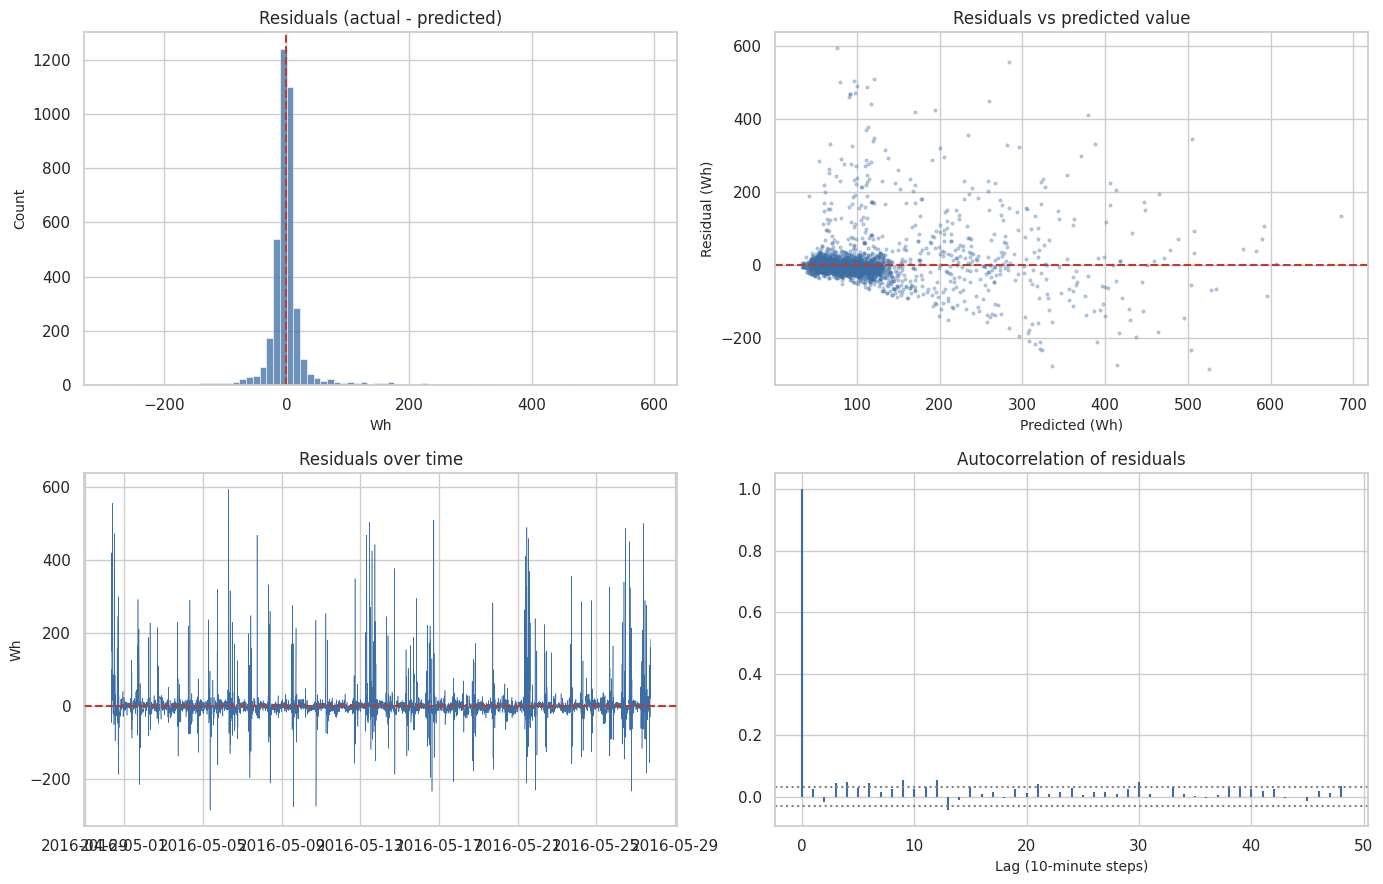

Mean residual (bias): 4.47 Wh | residual std: 56.34 Wh


In [ ]:
# 10.8 Residual analysis
residual = y_test_true - final_test
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
sns.histplot(residual, bins=80, ax=axes[0, 0], color='#3b6ea5')
axes[0, 0].axvline(0, color='#c0392b', ls='--')
axes[0, 0].set_title('Residuals (actual - predicted)')
axes[0, 0].set_xlabel('Wh')
axes[0, 1].scatter(final_test, residual, s=4, alpha=0.3, color='#3b6ea5')
axes[0, 1].axhline(0, color='#c0392b', ls='--')
axes[0, 1].set_title('Residuals vs predicted value')
axes[0, 1].set_xlabel('Predicted (Wh)')
axes[0, 1].set_ylabel('Residual (Wh)')
axes[1, 0].plot(test_times, residual, lw=0.4, color='#3b6ea5')
axes[1, 0].axhline(0, color='#c0392b', ls='--')
axes[1, 0].set_title('Residuals over time')
axes[1, 0].set_ylabel('Wh')
residual_acf = acf_values(residual, 48)
band = 1.96 / np.sqrt(len(residual))
axes[1, 1].vlines(range(len(residual_acf)), 0, residual_acf, color='#3b6ea5')
axes[1, 1].axhline(band, color='grey', ls=':')
axes[1, 1].axhline(-band, color='grey', ls=':')
axes[1, 1].set_title('Autocorrelation of residuals')
axes[1, 1].set_xlabel('Lag (10-minute steps)')
save_fig('residual_analysis')
print(f'Mean residual (bias): {residual.mean():.2f} Wh | residual std: {residual.std():.2f} Wh')

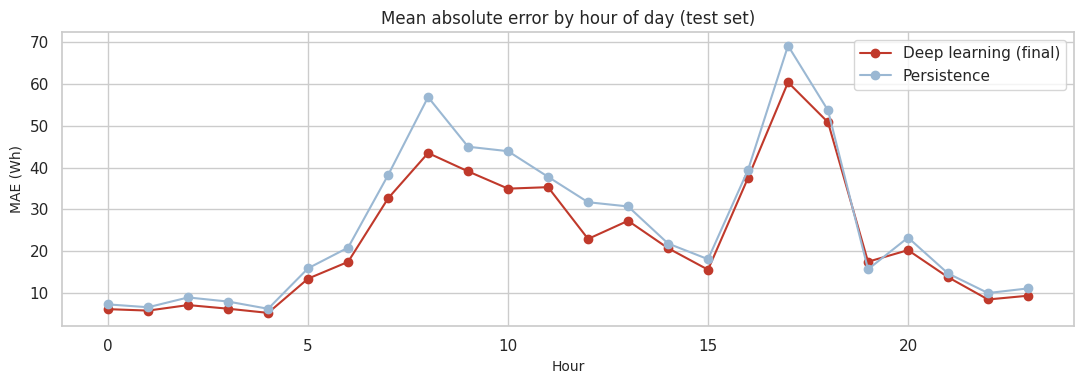

,readings,MAE_final,MAE_persistence,mean_actual,mean_predicted
level,,,,,
<=50 Wh,1092,8.62,8.77,47.53,55.64
50-100 Wh,2028,12.40,14.10,72.55,75.78
100-200 Wh,502,28.06,37.71,129.98,130.58
200-400 Wh,234,95.77,118.25,288.33,230.32
>400 Wh,91,223.38,224.29,534.51,317.12


In [ ]:
# 10.9 Where does the model do well and where does it struggle?
analysis = pd.DataFrame({'actual': y_test_true, 'final': final_test, 'persistence': persist_test,
                         'hour': test_times.hour})
analysis['abs_err_final'] = (analysis['actual'] - analysis['final']).abs()
analysis['abs_err_persistence'] = (analysis['actual'] - analysis['persistence']).abs()

by_hour = analysis.groupby('hour')[['abs_err_final', 'abs_err_persistence']].mean()
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(by_hour.index, by_hour['abs_err_final'], marker='o', color='#c0392b', label='Deep learning (final)')
ax.plot(by_hour.index, by_hour['abs_err_persistence'], marker='o', color='#9bb8d3', label='Persistence')
ax.set_title('Mean absolute error by hour of day (test set)')
ax.set_xlabel('Hour')
ax.set_ylabel('MAE (Wh)')
ax.legend()
save_fig('error_by_hour')

analysis['level'] = pd.cut(analysis['actual'], [0, 50, 100, 200, 400, 5000],
                           labels=['<=50 Wh', '50-100 Wh', '100-200 Wh', '200-400 Wh', '>400 Wh'])
by_level = analysis.groupby('level', observed=True).agg(
    readings=('actual', 'size'), MAE_final=('abs_err_final', 'mean'), MAE_persistence=('abs_err_persistence', 'mean'),
    mean_actual=('actual', 'mean'), mean_predicted=('final', 'mean')).round(2)
save_table(by_level, 'error_by_consumption_level')
by_level

## 11. One-hour-ahead check
The main task predicts 10 minutes ahead. A one-hour forecast (6 steps ahead) is harder, because the recent past says less about the more distant future. As an extra check we repeat the pipeline with the target moved 6 steps ahead, using the **same selected features and the same final configurations** (one run each, no new tuning). The calendar features and the "typical usage" feature are shifted to describe the moment being predicted.

In [68]:
# 11.1 Horizon = 6 steps (1 hour)
bundle6 = prepare_bundle(6)
baseline6_results, _, _ = run_baselines(bundle6)
y_test_6 = bundle6['y'][bundle6['masks']['test']]

main_6 = train_model(MAIN_CFG, bundle6, seed=SEED, keep_model=True)
companion_6 = train_model(COMPANION_CFG, bundle6, seed=SEED)
blend_6_test = BLEND_WEIGHT * main_6['pred_test'] + (1 - BLEND_WEIGHT) * companion_6['pred_test']
assert len(blend_6_test) == len(y_test_6)
main_6['model'].save(str(MODEL_DIR / 'model_horizon_1h.keras'))

rows_1h = []
for _, row in baseline6_results[baseline6_results['Set'] == 'Test'].iterrows():
    rows_1h.append({'Model': row['Model'], 'MAE': row['MAE'], 'RMSE': row['RMSE'], 'MAPE %': row['MAPE %'], 'R2': row['R2']})
for name, pred in [(f'{arch_label} main model (single run)', main_6['pred_test']),
                   (f'{arch_label} companion model (single run)', companion_6['pred_test']),
                   (f'{arch_label} blend (single runs)', blend_6_test)]:
    rows_1h.append({'Model': name, **regression_metrics(y_test_6, pred)})
horizon_table = pd.DataFrame(rows_1h).set_index('Model').round(3)
save_table(horizon_table, 'horizon_1h_results')
horizon_table
# print(horizon_table)

,MAE,RMSE,MAPE %,R2
Model,,,,
Persistence (last value),47.930,104.109,41.150,-0.308
Moving average (1 hour),44.407,90.292,40.051,0.016
Linear Regression,41.007,80.996,39.302,0.208
Random Forest,41.674,80.282,40.120,0.222
Random Forest (log target),35.831,79.988,29.077,0.228
Gradient Boosting,41.725,81.651,39.512,0.196
Gradient Boosting (log target),36.374,80.550,29.616,0.217
CNN-LSTM main model (single run),34.393,77.596,29.374,0.274
CNN-LSTM companion model (single run),36.576,80.971,30.230,0.209


## 12. Saving the results

In [69]:
# 12.1 Save the models, the configuration and the logs
ensemble_dir = MODEL_DIR / 'ensemble'
ensemble_dir.mkdir(exist_ok=True)
for label, runs in [('main', main_runs), ('companion', companion_runs)]:
    for run in runs:
        run['model'].save(str(ensemble_dir / f"{label}_seed{run['seed']}.keras"))

main_runs[0]['model'].save(str(MODEL_DIR / 'trained_model.keras'))
try:
    main_runs[0]['model'].save(str(MODEL_DIR / 'trained_model.h5'))       # older format, as in the assignment example
except Exception as error:
    print('Could not save .h5 (the .keras file is saved):', error)

with open(MODEL_DIR / 'final_config.json', 'w') as f:
    json.dump({'main_config': MAIN_CFG, 'companion_config': COMPANION_CFG, 'blend_weight_of_main_model': BLEND_WEIGHT,
               'selected_features': SELECTED, 'lags': LAGS, 'final_seeds': FINAL_SEEDS, 'horizon_steps': HORIZON},
              f, indent=1, default=str)
pd.DataFrame(experiment_log).to_csv(TAB_DIR / 'all_experiments.csv', index=False)

# requirements.txt with the exact versions used in this run
packages = ['tensorflow', 'keras', 'numpy', 'pandas', 'scikit-learn', 'matplotlib', 'seaborn', 'joblib']
version_lines = []
for package in packages:
    try:
        version_lines.append(f'{package}=={metadata.version(package)}')
    except metadata.PackageNotFoundError:
        pass
(ROOT / 'requirements.txt').write_text('\n'.join(version_lines) + '\n')
print('requirements.txt written:\n' + '\n'.join(version_lines))

requirements.txt written:
tensorflow==2.21.0
keras==3.13.2
numpy==2.1.3
pandas==2.2.3
scikit-learn==1.6.1
matplotlib==3.10.0
seaborn==0.13.2
joblib==1.6.0


In [70]:
# 12.2 Bundle everything to zip file
final_row = results.loc[FINAL_NAME]
summary = {'n_selected_features': len(SELECTED), 'selected_features': SELECTED, 'best_architecture': BEST_ARCH,
           'main_config': MAIN_CFG, 'companion_config': COMPANION_CFG, 'blend_weight_of_main_model': BLEND_WEIGHT,
           'final_seeds': FINAL_SEEDS, 'test_start': str(TEST_START),
           'final_test_metrics': {k: float(final_row[k]) for k in ['Test MAE', 'Test RMSE', 'Test MAPE %', 'Test R2']},
           'library_versions': {line.split('==')[0]: line.split('==')[1] for line in version_lines}}
(TAB_DIR / 'run_summary.json').write_text(json.dumps(summary, indent=1, default=float))

zip_path = ROOT / 'reports' / 'results_bundle.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as z:
    for folder in [FIG_DIR, TAB_DIR]:
        for file in sorted(folder.glob('*')):
            z.write(file, arcname=f'{folder.name}/{file.name}')
    z.write(MODEL_DIR / 'final_config.json', arcname='final_config.json')
    z.write(ROOT / 'requirements.txt', arcname='requirements.txt')
print('Created', zip_path, f'({zip_path.stat().st_size / 1e6:.1f} MB)')
try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    pass

Created /content/reports/results_bundle.zip (2.6 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. Summary
The next cell prints the key numbers automatically, so the text always matches the latest run.

In [71]:
# 13.1 summary of the run
persistence_row = results.loc['Persistence (last value)']
baseline_only = results[results['Type'] == 'Baseline']
best_baseline_rmse = baseline_only['Test RMSE'].idxmin()
best_baseline_mae = baseline_only['Test MAE'].idxmin()

print(f'Best architecture (validation): {BEST_ARCH}')
print(f'Main model     ({MAIN_FAMILY} target): {MAIN_CFG}')
print(f'Companion model ({COMPANION_FAMILY} target): {COMPANION_CFG}')
print(f'Blend weight of the main model: {BLEND_WEIGHT:.2f}')
print(f'Selected features: {len(SELECTED)}\n')

print(f"FINAL BLEND   test MAE {final_row['Test MAE']:.2f} | RMSE {final_row['Test RMSE']:.2f} | "
      f"MAPE {final_row['Test MAPE %']:.1f}% | R2 {final_row['Test R2']:.3f}")
print(f"Persistence   test MAE {persistence_row['Test MAE']:.2f} | RMSE {persistence_row['Test RMSE']:.2f} | "
      f"MAPE {persistence_row['Test MAPE %']:.1f}% | R2 {persistence_row['Test R2']:.3f}")
print(f"Lower than persistence: MAE {(1 - final_row['Test MAE'] / persistence_row['Test MAE']) * 100:.1f}% | "
      f"RMSE {(1 - final_row['Test RMSE'] / persistence_row['Test RMSE']) * 100:.1f}%")
print(f"Best baseline by MAE : {best_baseline_mae} ({baseline_only.loc[best_baseline_mae, 'Test MAE']:.2f})")
print(f"Best baseline by RMSE: {best_baseline_rmse} ({baseline_only.loc[best_baseline_rmse, 'Test RMSE']:.2f})")
print('Final model beats the best baseline on MAE :', bool(final_row['Test MAE'] < baseline_only['Test MAE'].min()))
print('Final model beats the best baseline on RMSE:', bool(final_row['Test RMSE'] < baseline_only['Test RMSE'].min()))

Best architecture (validation): cnn_lstm
Main model     (raw target): {'arch': 'cnn_lstm', 'window': 24, 'units': 32, 'n_layers': 1, 'dropout': 0.1, 'l2': 0.0001, 'dense_units': 16, 'lr': 0.003, 'batch_size': 256, 'optimizer': 'adam', 'loss': 'huber', 'target_mode': 'raw'}
Companion model (log target): {'arch': 'cnn_lstm', 'window': 48, 'units': 128, 'n_layers': 2, 'dropout': 0.4, 'l2': 1e-05, 'dense_units': 16, 'lr': 0.003, 'batch_size': 128, 'optimizer': 'adam', 'loss': 'mse', 'target_mode': 'log'}
Blend weight of the main model: 0.65
Selected features: 15

FINAL BLEND   test MAE 23.15 | RMSE 56.52 | MAPE 19.6% | R2 0.615
Persistence   test MAE 26.65 | RMSE 66.44 | MAPE 21.9% | R2 0.467
Lower than persistence: MAE 13.1% | RMSE 14.9%
Best baseline by MAE : Gradient Boosting (log target) (23.64)
Best baseline by RMSE: Random Forest (58.12)
Final model beats the best baseline on MAE : True
Final model beats the best baseline on RMSE: True


In [72]:
  !zip -r /content/models.zip /content/models
  from google.colab import files
  files.download('/content/models.zip')

  adding: content/models/ (stored 0%)
  adding: content/models/model_horizon_1h.keras (deflated 26%)
  adding: content/models/trained_model.keras (deflated 25%)
  adding: content/models/trained_model.h5 (deflated 27%)
  adding: content/models/feature_scaler.joblib (deflated 29%)
  adding: content/models/ensemble/ (stored 0%)
  adding: content/models/ensemble/companion_seed99.keras (deflated 8%)
  adding: content/models/ensemble/main_seed11.keras (deflated 26%)
  adding: content/models/ensemble/main_seed7.keras (deflated 26%)
  adding: content/models/ensemble/main_seed2024.keras (deflated 26%)
  adding: content/models/ensemble/companion_seed2024.keras (deflated 8%)
  adding: content/models/ensemble/companion_seed7.keras (deflated 8%)
  adding: content/models/ensemble/main_seed42.keras (deflated 25%)
  adding: content/models/ensemble/main_seed99.keras (deflated 26%)
  adding: content/models/ensemble/companion_seed42.keras (deflated 8%)
  adding: content/models/ensemble/companion_seed11.k

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Notes for the reader
- All numbers in the report come from one complete run of this notebook. Neural network training can vary slightly between runs and between GPU types, which is why the final models are averages of several seeds and why seeds and library versions are recorded.
- The test set was used only after all choices (features, architecture, hyperparameters, blend weight) were fixed using the validation set.
- The validation predictions of the networks are slightly optimistic, because early stopping and model selection used the same data. This is why the number of seeds is large and why the candidates were re-tested with new seeds.
- **Limits of this study:** only about 4.5 months of data from one house; one-step-ahead evaluation on one time split (a walk-forward evaluation would give a stronger estimate); the public-holiday list assumes the house is in Belgium; very high spikes remain hard to predict from past energy and indoor sensors alone.